In [45]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os
import tables
import pathlib
from IPython.display import display
from matplotlib.colors import Normalize
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score


import warnings
warnings.filterwarnings("ignore")
    
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

### Datasets

In [46]:
corrs = load('res_data/correlations.joblib')

In [47]:
proteomics = load('res_data/proteomics_matched.joblib')

In [48]:
tables.file._open_files.close_all()
p = pathlib.Path(r"res_data/enet_all_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
# Load all data from the HDF5 file
h5_file = 'res_data/enet_all_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)
print("Combined DataFrame shape:", combined_df.shape)


exists: True size: 175217074 bytes
Combined DataFrame shape: (1886697, 5)


In [49]:
combined_df

,protein,LOO sample,true,predicted,params_dict
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
...,...,...,...,...,...
1886692,ZZZ3,FADU_UPPER_AERODIGESTIVE_TRACT,-0.005547,0.460213,"{""alpha"": 0.5, ""l1_ratio"": 0.1}"
1886693,ZZZ3,KP4_PANCREAS,1.008579,-0.192050,"{""alpha"": 0.5, ""l1_ratio"": 0.1}"
1886694,ZZZ3,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-0.157715,0.069767,"{""alpha"": 1, ""l1_ratio"": 0.1}"
1886695,ZZZ3,OVCAR8_OVARY,0.196810,-0.045903,"{""alpha"": 1, ""l1_ratio"": 0.1}"


## Rescaled Analysis, 

scTranslator-style per-sample min–max normalization.

they achieve the following results with 10k model: 20000 RNA -> 1000 Protein
Test Set: AVG mse 0.0487, AVG ccc 0.8979

#### Rescale [10e-8, 1]

In [ ]:
# for scaling using truth min/max scale
# EPS = 1e-8

# df = combined_df.copy()
# df["true"] = pd.to_numeric(df["true"], errors="coerce")
# df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

# # basic normalization with supplied min/max
# def normalization_with_minmax(x: pd.Series, xmin: float, xmax: float,
#                               low: float = EPS, high: float = 1.0) -> pd.Series:
#     if pd.isna(xmin) or pd.isna(xmax) or xmax == xmin:
#         return pd.Series(low, index=x.index, dtype="float64")
#     return low + (x - xmin) / (xmax - xmin) * (high - low)

# mm = df.groupby("LOO sample", observed=True)["true"].agg(tmin="min", tmax="max")
# df = df.merge(mm, left_on="LOO sample", right_index=True, how="left")

# # true uses its own min/max; pred uses truth's min/max
# df["true_mm"] = df.groupby("LOO sample", observed=True).apply(
#     lambda g: normalization_with_minmax(g["true"], g["tmin"].iloc[0], g["tmax"].iloc[0])
# ).reset_index(level=0, drop=True)

# df["pred_mm"] = df.groupby("LOO sample", observed=True).apply(
#     lambda g: normalization_with_minmax(g["predicted"], g["tmin"].iloc[0], g["tmax"].iloc[0])
# ).reset_index(level=0, drop=True)

# df["true_mm"] = df["true_mm"].clip(lower=EPS, upper=1.0)
# df["pred_mm"] = df["pred_mm"].clip(lower=EPS, upper=1.0)


In [ ]:
# to scale independently per sample using min/max of each vector, true and predicted separately
# scTranslator-style per-sample min–max normalization for a long DataFrame
# expected columns in `combined_df`: ["protein", "LOO sample", "true", "predicted"]

EPS = 1e-8  # lower bound in the target scale

# --- sanity checks
required_cols = {"protein", "LOO sample", "true", "predicted"}
missing = required_cols - set(combined_df.columns)
if missing:
    raise ValueError(f"combined_df is missing required columns: {sorted(missing)}")

df = combined_df.copy()

# ensure numeric
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

# scTranslator-style normalization, safe for constant vectors / NaNs
def normalization(x: pd.Series, low: float = EPS, high: float = 1.0) -> pd.Series:
    # x is a Series for a single sample's vector (across proteins)
    xmin = x.min(skipna=True)
    xmax = x.max(skipna=True)
    if pd.isna(xmin) or pd.isna(xmax):
        # all NaNs -> return NaNs (or low, if you prefer)
        return pd.Series(np.nan, index=x.index, dtype="float64")
    if xmax == xmin:
        # constant vector -> map everything to `low`
        return pd.Series(low, index=x.index, dtype="float64")
    return low + (x - xmin) / (xmax - xmin) * (1.0 - low)

# normalize per sample, separately for true and predicted
df["true_mm"] = df.groupby("LOO sample", observed=True)["true"].transform(normalization)
df["pred_mm"] = df.groupby("LOO sample", observed=True)["predicted"].transform(normalization)

# clip to be extra-safe against tiny floating drift
df["true_mm"] = df["true_mm"].clip(lower=EPS, upper=1.0)
df["pred_mm"] = df["pred_mm"].clip(lower=EPS, upper=1.0)

# quick validation
print("Ranges after scaling:")
print("  true_mm :", float(np.nanmin(df["true_mm"])), "→", float(np.nanmax(df["true_mm"])))
print("  pred_mm :", float(np.nanmin(df["pred_mm"])), "→", float(np.nanmax(df["pred_mm"])))

# OPTIONAL: per-protein Pearson r on the min–max scale
want_metrics = True
if want_metrics:
    t_mat = df.pivot(index="LOO sample", columns="protein", values="true_mm")
    p_mat = df.pivot(index="LOO sample", columns="protein", values="pred_mm")

    common = t_mat.columns.intersection(p_mat.columns)
    t_mat = t_mat[common]
    p_mat = p_mat[common]

    t = t_mat.to_numpy(dtype=float)
    p = p_mat.to_numpy(dtype=float)

    t_z = t - np.nanmean(t, axis=0, keepdims=True)
    p_z = p - np.nanmean(p, axis=0, keepdims=True)

    num = np.nansum(t_z * p_z, axis=0)
    den = np.sqrt(np.nansum(t_z**2, axis=0) * np.nansum(p_z**2, axis=0))
    r = np.divide(num, den, out=np.full_like(num, np.nan, dtype=float), where=den!=0)

    per_protein_corr = pd.Series(r, index=common, name="pearson_r").sort_values(ascending=False)
    print("\nPer-protein Pearson r (first 10):")
    print(per_protein_corr.head(10))

# df now contains:
#   - 'true_mm' : truth scaled to [1e-8, 1] per sample using its *own* min/max
#   - 'pred_mm' : predictions scaled to [1e-8, 1] per sample using their *own* min/max


Ranges after scaling:
  true_mm : 1e-08 → 1.0
  pred_mm : 1e-08 → 1.0

Per-protein Pearson r (first 10):
protein
BASP1       0.853678
EPCAM       0.805745
S100A14     0.793624
MAGEA4      0.791338
TACSTD2     0.789501
ST14        0.775901
CA2         0.774254
SERPINB5    0.774187
PDLIM4      0.773463
IGF2BP1     0.772038
Name: pearson_r, dtype: float64


In [63]:
# === Per-protein Pearson r AND Cosine similarity (NaN-safe), plus MSE ===
# Uses the min–max columns if present; otherwise falls back to raw.

TRUE_COL = "true_mm"  if "true_mm"  in df.columns else "true"
PRED_COL = "pred_mm"  if "pred_mm"  in df.columns else "predicted"
print(f"Evaluating on columns: TRUE={TRUE_COL}  PRED={PRED_COL}")

# Pivot to samples × proteins matrices
T = df.pivot(index="LOO sample", columns="protein", values=TRUE_COL).astype(float)
P = df.pivot(index="LOO sample", columns="protein", values=PRED_COL).astype(float)

# Align columns
common = T.columns.intersection(P.columns)
T = T[common]
P = P[common]

t = T.to_numpy(dtype=float)
p = P.to_numpy(dtype=float)

# ---------- Pearson r (column-wise) ----------
t_z = t - np.nanmean(t, axis=0, keepdims=True)
p_z = p - np.nanmean(p, axis=0, keepdims=True)

num_r = np.nansum(t_z * p_z, axis=0)
den_r = np.sqrt(np.nansum(t_z**2, axis=0) * np.nansum(p_z**2, axis=0))
pearson_r = np.divide(num_r, den_r, out=np.full_like(num_r, np.nan, dtype=float), where=den_r != 0)

# ---------- Cosine similarity (column-wise; uncentered) ----------
mask = ~(np.isnan(t) | np.isnan(p))
num_c = np.nansum(np.where(mask, t * p, 0.0), axis=0)
t_norm = np.sqrt(np.nansum(np.where(mask, t * t, 0.0), axis=0))
p_norm = np.sqrt(np.nansum(np.where(mask, p * p, 0.0), axis=0))
den_c = t_norm * p_norm
cosine = np.divide(num_c, den_c, out=np.full_like(num_c, np.nan, dtype=float), where=den_c != 0)

# ---------- MSE (column-wise) ----------
mse = np.nanmean((t - p) ** 2, axis=0)

# Assemble table
per_protein_metrics = pd.DataFrame(
    {"pearson_r": pearson_r, "cosine": cosine, "mse": mse},
    index=common
).sort_values("cosine", ascending=False)

# Show top by cosine
TOP_N = 30
print(f"\nTop {TOP_N} proteins by cosine similarity:")
display(per_protein_metrics.head(TOP_N))

# Also useful: top by Pearson (for comparison)
print(f"\nTop {TOP_N} proteins by Pearson r:")
display(per_protein_metrics.sort_values("pearson_r", ascending=False).head(TOP_N))

# Save full table
per_protein_metrics.to_csv("per_protein_metrics_pearson_cosine_mse.csv")
print("\nSaved: per_protein_metrics_pearson_cosine_mse.csv")


Evaluating on columns: TRUE=true_mm  PRED=pred_mm

Top 30 proteins by cosine similarity:


,pearson_r,cosine,mse
protein,,,
PSMC3,0.196711,0.976312,0.012790
TIAL1,0.239969,0.976178,0.012874
PSMC6,0.191453,0.976109,0.012856
MED22,0.218284,0.975749,0.013124
WAPAL,0.146807,0.975715,0.013066
VCP,0.150471,0.975707,0.013088
UFD1L,0.168176,0.975682,0.013114
SART1,0.257660,0.975665,0.013151
HCFC1,0.244144,0.975577,0.013176



Top 30 proteins by Pearson r:


,pearson_r,cosine,mse
protein,,,
BASP1,0.853678,0.948446,0.034336
EPCAM,0.805745,0.941196,0.034291
S100A14,0.793624,0.943002,0.031999
MAGEA4,0.791338,0.952153,0.024151
TACSTD2,0.789501,0.950990,0.026165
ST14,0.775901,0.951646,0.025520
CA2,0.774254,0.942762,0.028933
SERPINB5,0.774187,0.951477,0.025609
PDLIM4,0.773463,0.953330,0.025372



Saved: per_protein_metrics_pearson_cosine_mse.csv


In [64]:
# Add R^2 from Pearson r and save an updated CSV

assert "per_protein_metrics" in globals(), "per_protein_metrics not found. Run the metrics cell first."
m = per_protein_metrics.copy()

m["r2"] = np.square(m["pearson_r"])
per_protein_metrics = m  # keep the name consistent downstream

per_protein_metrics.to_csv("per_protein_metrics_pearson_cosine_mse_r2.csv")
print("Saved: per_protein_metrics_pearson_cosine_mse_r2.csv")
display(per_protein_metrics.head())


Saved: per_protein_metrics_pearson_cosine_mse_r2.csv


,pearson_r,cosine,mse,r2
protein,,,,
PSMC3,0.196711,0.976312,0.012790,0.038695
TIAL1,0.239969,0.976178,0.012874,0.057585
PSMC6,0.191453,0.976109,0.012856,0.036654
MED22,0.218284,0.975749,0.013124,0.047648
WAPAL,0.146807,0.975715,0.013066,0.021552


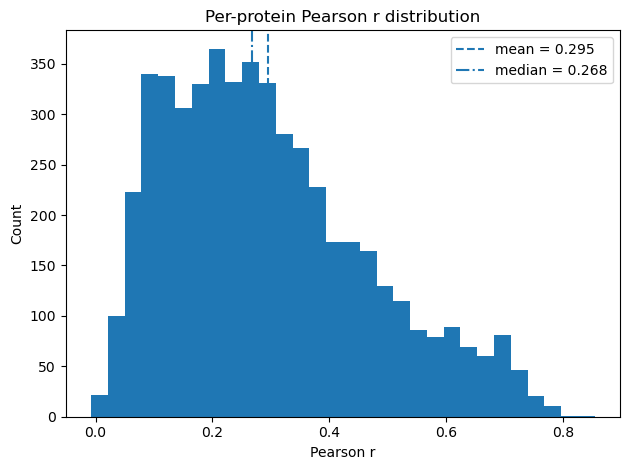

n=5113 | mean=0.295 | median=0.268 | std=0.171


In [65]:
# Histogram of per-protein Pearson r

vals = per_protein_metrics["pearson_r"].dropna().to_numpy()
mean_v = float(np.nanmean(vals)) if len(vals) else np.nan
med_v  = float(np.nanmedian(vals)) if len(vals) else np.nan

plt.figure()
plt.hist(vals, bins=30)
if np.isfinite(mean_v):
    plt.axvline(mean_v, linestyle="--", linewidth=1.5, label=f"mean = {mean_v:.3f}")
if np.isfinite(med_v):
    plt.axvline(med_v, linestyle="-.", linewidth=1.5, label=f"median = {med_v:.3f}")
plt.xlabel("Pearson r")
plt.ylabel("Count")
plt.title("Per-protein Pearson r distribution")
plt.legend()
plt.tight_layout()
plt.show()

print(f"n={len(vals)} | mean={mean_v:.3f} | median={med_v:.3f} | std={np.nanstd(vals):.3f}")


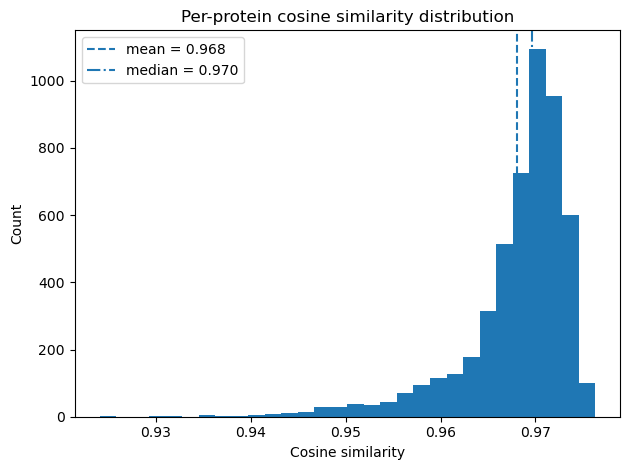

n=5113 | mean=0.968 | median=0.970 | std=0.006


In [66]:
# === Plot cosine similarity distribution ===
vals = per_protein_metrics["cosine"].dropna().to_numpy()
mean_v = float(np.nanmean(vals)) if len(vals) else np.nan
med_v  = float(np.nanmedian(vals)) if len(vals) else np.nan

plt.figure()
plt.hist(vals, bins=30)
if np.isfinite(mean_v):
    plt.axvline(mean_v, linestyle="--", linewidth=1.5, label=f"mean = {mean_v:.3f}")
if np.isfinite(med_v):
    plt.axvline(med_v, linestyle="-.", linewidth=1.5, label=f"median = {med_v:.3f}")
plt.xlabel("Cosine similarity")
plt.ylabel("Count")
plt.title("Per-protein cosine similarity distribution")
plt.legend()
plt.tight_layout()
plt.show()

print(f"n={len(vals)} | mean={mean_v:.3f} | median={med_v:.3f} | std={np.nanstd(vals):.3f}")


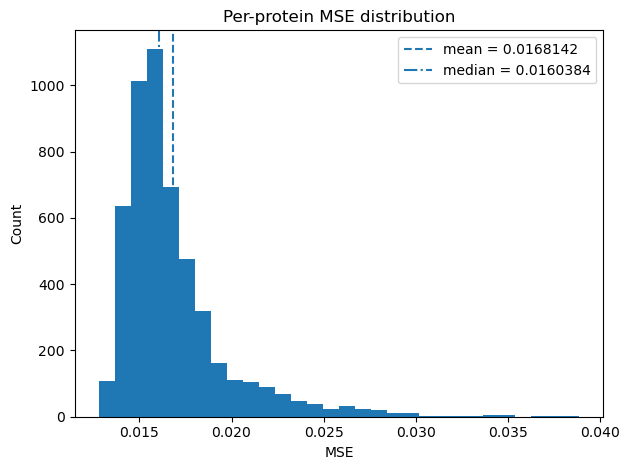

n=5113 | mean=0.0168142 | median=0.0160384 | std=0.00291241


In [67]:
# === Plot mse distribution ===
vals = per_protein_metrics["mse"].dropna().to_numpy()
mean_v = float(np.nanmean(vals)) if len(vals) else np.nan
med_v  = float(np.nanmedian(vals)) if len(vals) else np.nan

plt.figure()
plt.hist(vals, bins=30)
if np.isfinite(mean_v):
    plt.axvline(mean_v, linestyle="--", linewidth=1.5, label=f"mean = {mean_v:.6g}")
if np.isfinite(med_v):
    plt.axvline(med_v, linestyle="-.", linewidth=1.5, label=f"median = {med_v:.6g}")
plt.xlabel("MSE")
plt.ylabel("Count")
plt.title("Per-protein MSE distribution")
plt.legend()
plt.tight_layout()
plt.show()

print(f"n={len(vals)} | mean={mean_v:.6g} | median={med_v:.6g} | std={np.nanstd(vals):.6g}")


In [ ]:
# Summary counts/percentages for cosine, R^2, and MSE thresholds + metric means

assert "per_protein_metrics" in globals(), "per_protein_metrics not found. Run the metrics cell first."
m = per_protein_metrics.copy()

# Ensure R^2 exists
if "r2" not in m.columns:
    m["r2"] = np.square(m["pearson_r"])

def summarize_thresholds(series: pd.Series, thresholds, direction: str, metric_name: str):
    """
    direction: 'gt' for series > thr, 'lt' for series < thr
    Returns list of dict rows with count and percent (NaNs excluded).
    """
    s = series.astype(float)
    n = int(s.notna().sum())
    rows = []
    for thr in thresholds:
        if direction == "gt":
            mask = s > thr
            sign = ">"
        elif direction == "lt":
            mask = s < thr
            sign = "<"
        else:
            raise ValueError('direction must be "gt" or "lt"')
        cnt = int(mask.sum(skipna=True))
        pct = (cnt / n * 100.0) if n else np.nan
        rows.append({
            "metric": metric_name,
            "threshold": float(thr),
            "direction": sign,
            "count": cnt,
            "percent": pct,
            "n": n
        })
    return rows

rows = []
rows += summarize_thresholds(m["cosine"], [0.95, 0.96, 0.97, 0.98], "gt", "cosine")
rows += summarize_thresholds(m["r2"],     [0.3, 0.4, 0.5, 0.6], "gt", "r2")
rows += summarize_thresholds(m["mse"],    [0.05, 0.04, 0.03, 0.02, 0.015, 0.01], "lt", "mse")

results = pd.DataFrame(rows)

# Order rows nicely: cosine, r2, mse; show '>' before '<'; thresholds ascending within each metric/direction
results["metric"] = pd.Categorical(results["metric"], categories=["cosine", "r2", "mse"], ordered=True)
results = results.sort_values(["metric", "direction", "threshold"], ascending=[True, False, True]).reset_index(drop=True)

# Round for a clean look and add a readable threshold label
results["percent"] = results["percent"].round(1)
results["threshold"] = results["threshold"].round(3)
results["rule"] = results["direction"] + " " + results["threshold"].astype(str)
results = results[["metric", "rule", "count", "percent", "n"]].rename(columns={"percent": "percent (%)"})

# Display the final result table
display(results)

# Also print means across proteins for the main metrics
means = m[["pearson_r", "cosine", "mse", "r2"]].mean(skipna=True)
print("Means across proteins:")
print(f"  Pearson r:        {means['pearson_r']:.3f}")
print(f"  Cosine similarity:{means['cosine']:.3f}")
print(f"  MSE:              {means['mse']:.6g}")
print(f"  R^2:              {means['r2']:.3f}")


,metric,rule,count,percent (%),n
0,cosine,> 0.95,5006,97.9,5113
1,cosine,> 0.96,4648,90.9,5113
2,cosine,> 0.97,2355,46.1,5113
3,cosine,> 0.98,0,0.0,5113
4,r2,> 0.3,516,10.1,5113
5,r2,> 0.4,270,5.3,5113
6,r2,> 0.5,82,1.6,5113
7,r2,> 0.6,6,0.1,5113
8,mse,< 0.015,1261,24.7,5113
9,mse,< 0.02,4558,89.1,5113


Means across proteins:
  Pearson r:        0.295
  Cosine similarity:0.968
  MSE:              0.0168142
  R^2:              0.116


### Samples


In [75]:
# ---------- Per-sample metrics (across proteins) on normalized values ----------
# Rows = LOO samples, Cols = metrics [mse, r2, cosine]
need = {"LOO sample", "protein", "true_mm", "pred_mm"}
missing = need - set(df.columns)
assert not missing, f"df is missing required columns: {sorted(missing)}"

# pivot to samples x proteins matrices
T = df.pivot(index="LOO sample", columns="protein", values="true_mm").astype(float)
P = df.pivot(index="LOO sample", columns="protein", values="pred_mm").astype(float)

# align protein columns
common = T.columns.intersection(P.columns)
T = T[common]
P = P[common]

samples = T.index.to_numpy()
t = T.to_numpy(dtype=float)  # shape: [n_samples, n_proteins]
p = P.to_numpy(dtype=float)

# paired mask across proteins within each sample
mask = ~(np.isnan(t) | np.isnan(p))

# --- MSE per sample (across proteins) ---
sqerr = np.where(mask, (t - p) ** 2, np.nan)
mse = np.nanmean(sqerr, axis=1)

# --- Cosine similarity per sample (uncentered; across proteins) ---
num_c = np.nansum(np.where(mask, t * p, 0.0), axis=1)
t_norm = np.sqrt(np.nansum(np.where(mask, t * t, 0.0), axis=1))
p_norm = np.sqrt(np.nansum(np.where(mask, p * p, 0.0), axis=1))
den_c = t_norm * p_norm
cosine = np.divide(num_c, den_c, out=np.full_like(num_c, np.nan), where=den_c != 0)

# --- Pearson r and R^2 per sample (pairwise across proteins) ---
t_pair = np.where(mask, t, np.nan)
p_pair = np.where(mask, p, np.nan)
t_mean = np.nanmean(t_pair, axis=1, keepdims=True)
p_mean = np.nanmean(p_pair, axis=1, keepdims=True)

t_c = np.where(mask, t_pair - t_mean, 0.0)
p_c = np.where(mask, p_pair - p_mean, 0.0)

num_r = np.nansum(t_c * p_c, axis=1)
den_r = np.sqrt(np.nansum(t_c**2, axis=1) * np.nansum(p_c**2, axis=1))
pearson_r = np.divide(num_r, den_r, out=np.full_like(num_r, np.nan), where=den_r != 0)
r2 = np.square(pearson_r)

# --- assemble results ---
per_sample_metrics = pd.DataFrame(
    {"mse": mse, "r2": r2, "cosine": cosine},
    index=T.index
)

# also provide a long (stacked) version if we want metrics as rows too
per_sample_metrics_long = per_sample_metrics.stack().to_frame("value")
per_sample_metrics_long.index.set_names(["LOO sample", "metric"], inplace=True)

# show a peek and save
display(per_sample_metrics.head())
display(per_sample_metrics_long.head(9))

per_sample_metrics.to_csv("per_sample_metrics_mse_r2_cosine.csv")
print("Saved: per_sample_metrics_mse_r2_cosine.csv")

,mse,r2,cosine
LOO sample,,,
22RV1_PROSTATE,0.006625,0.405660,0.990179
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.006213,0.636011,0.988982
769P_KIDNEY,0.007117,0.591885,0.990764
786O_KIDNEY,0.010046,0.425653,0.986676
8305C_THYROID,0.006866,0.394760,0.984207


value
LOO sample                             metric          
22RV1_PROSTATE                         mse     0.006625
                                       r2      0.405660
                                       cosine  0.990179
697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE mse     0.006213
                                       r2      0.636011
                                       cosine  0.988982
769P_KIDNEY                            mse     0.007117
                                       r2      0.591885
                                       cosine  0.990764

Saved: per_sample_metrics_mse_r2_cosine.csv


In [76]:
# Summary counts/percentages for per-sample cosine, R^2, and MSE thresholds + metric means
assert "per_sample_metrics" in globals(), "per_sample_metrics not found. Run the per-sample metrics cell first."
m = per_sample_metrics.copy()

# Ensure required metrics exist
if "r2" not in m.columns:
    if "pearson_r" in m.columns:
        m["r2"] = np.square(m["pearson_r"])
    else:
        raise AssertionError("per_sample_metrics must include 'r2' or 'pearson_r' to derive R^2.")
for col in ("mse", "cosine", "r2"):
    assert col in m.columns, f"per_sample_metrics is missing required column '{col}'."

def summarize_thresholds(series: pd.Series, thresholds, direction: str, metric_name: str):
    """
    Compute counts/percentages across SAMPLES:
      - 'gt' counts s > thr
      - 'lt' counts s < thr
    NaNs are excluded from n.
    """
    s = series.astype(float)
    n = int(s.notna().sum())
    rows = []
    for thr in thresholds:
        if direction == "gt":
            mask = s > thr
            sign = ">"
        elif direction == "lt":
            mask = s < thr
            sign = "<"
        else:
            raise ValueError('direction must be "gt" or "lt"')
        cnt = int(mask.sum(skipna=True))
        pct = (cnt / n * 100.0) if n else np.nan
        rows.append({
            "metric": metric_name,
            "threshold": float(thr),
            "direction": sign,
            "count": cnt,
            "percent": pct,
            "n_samples": n
        })
    return rows

rows = []
rows += summarize_thresholds(m["cosine"], [0.7, 0.8, 0.9], "gt", "cosine")
rows += summarize_thresholds(m["r2"],     [0.7, 0.8, 0.9], "gt", "r2")
rows += summarize_thresholds(m["mse"],    [0.05, 0.04, 0.03, 0.02, 0.01], "lt", "mse")

results = pd.DataFrame(rows)

# Order rows: cosine, r2, mse; show '>' before '<'; thresholds ascending
results["metric"] = pd.Categorical(results["metric"], categories=["cosine", "r2", "mse"], ordered=True)
results = results.sort_values(["metric", "direction", "threshold"], ascending=[True, False, True]).reset_index(drop=True)

# Round & pretty rule label
results["percent"] = results["percent"].round(1)
results["threshold"] = results["threshold"].round(3)
results["rule"] = results["direction"] + " " + results["threshold"].astype(str)
results = results[["metric", "rule", "count", "percent", "n_samples"]].rename(columns={"percent": "percent (%)"})

# Display the threshold summary
display(results)

# Means across SAMPLES for the main metrics
means = m[["mse", "r2", "cosine"]].mean(skipna=True)
means_df = pd.DataFrame([means]).rename(columns={"r2": "R^2", "cosine": "cosine", "mse": "MSE"})
print(f"Means across samples (n={len(m)}):")
print(f"  MSE:              {means['mse']:.6g}")
print(f"  R^2:              {means['r2']:.3f}")
print(f"  Cosine similarity:{means['cosine']:.3f}")
display(means_df)


,metric,rule,count,percent (%),n_samples
0,cosine,> 0.7,369,100.0,369
1,cosine,> 0.8,369,100.0,369
2,cosine,> 0.9,369,100.0,369
3,r2,> 0.7,6,1.6,369
4,r2,> 0.8,0,0.0,369
5,r2,> 0.9,0,0.0,369
6,mse,< 0.01,207,56.1,369
7,mse,< 0.02,284,77.0,369
8,mse,< 0.03,315,85.4,369
9,mse,< 0.04,329,89.2,369


Means across samples (n=369):
  MSE:              0.0168142
  R^2:              0.454
  Cosine similarity:0.989


,MSE,R^2,cosine
0,0.016814,0.45446,0.988667


##  Protein-wise analysis


Compute per-protein metrics

In [ ]:
combined_df

In [9]:

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()
# NEW: overall R² (same constant on all rows for convenience)
r2_overall = r2_score(combined_df['true'].values, combined_df['predicted'].values)
combined_df['r2_overall'] = r2_overall

combined_df.head()


,protein,LOO sample,true,predicted,params_dict,tmin,tmax,true_mm,pred_mm,abs_error,squared_error,rel_error,pearson_corr,cosine_similarity,r2_overall
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",-2.738984,3.891452,0.360975,0.371368,0.068912,4.748821e-03,0.199419,0.661559,0.661853,0.435739
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",-2.783085,3.560902,0.697554,0.487310,1.333784,1.778980e+00,0.812200,0.661559,0.661853,0.435739
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",-3.558878,4.295320,0.309359,0.338546,0.229246,5.255372e-02,0.203032,0.661559,0.661853,0.435739
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",-4.025870,3.364167,0.746844,0.514697,1.715576,2.943201e+00,1.148823,0.661559,0.661853,0.435739
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",-2.355036,4.222115,0.399822,0.399961,0.000913,8.334106e-07,0.003324,0.661559,0.661853,0.435739


R² by protein — summary:
count    5113.000000
mean        0.298352
std         0.189233
min        -0.086148
25%         0.149103
50%         0.260767
75%         0.427622
max         0.825527
Name: r2, dtype: float64


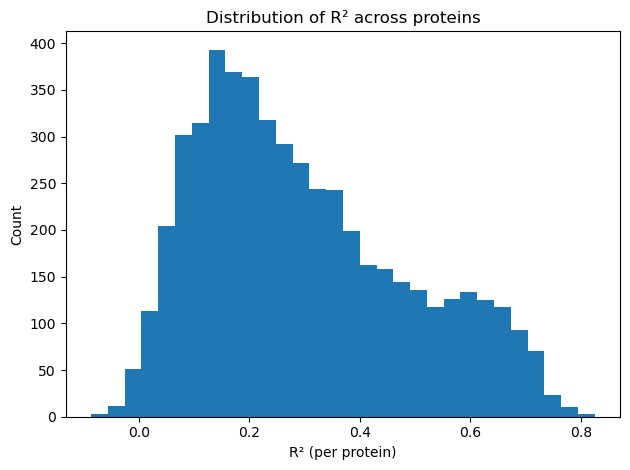


Top 10 proteins by R²:


,protein,r2
2016,IGF2BP1,0.825527
433,BASP1,0.817430
2346,MAGEA4,0.801495
1719,GNG12,0.783357
2363,MAP1B,0.783257
4526,TJP2,0.772144
1843,HCLS1,0.770159
924,CORO1A,0.770120
3655,RBM47,0.769908
2005,IFI16,0.769057



Bottom 10 proteins by R²:


,protein,r2
1023,CUL3,-0.086148
2779,NEDD1,-0.076207
4731,TUBG1,-0.066658
4337,STRIP1,-0.053569
1881,HIST1H1C,-0.043537
4861,USP36,-0.042857
3869,RRP8,-0.040022
409,AURKA,-0.039585
4675,TRIP4,-0.038423
2995,OTUB1,-0.036715


In [10]:


# Per-protein R² (across all LOO samples for that protein)
def _r2_group(g):
    y, yhat = g['true'].values, g['predicted'].values
    return r2_score(y, yhat) if (len(y) > 1 and np.var(y) > 0) else np.nan

r2_by_protein = (combined_df
                 .groupby('protein', dropna=False)
                 .apply(_r2_group)
                 .rename('r2')
                 .reset_index())

print("R² by protein — summary:")
print(r2_by_protein['r2'].describe())

# Histogram
plt.figure()
plt.hist(r2_by_protein['r2'].dropna().values, bins=30)
plt.xlabel('R² (per protein)')
plt.ylabel('Count')
plt.title('Distribution of R² across proteins')
plt.tight_layout()
plt.show()

# Optional: extremes
print("\nTop 10 proteins by R²:")
display(r2_by_protein.sort_values('r2', ascending=False).head(10))
print("\nBottom 10 proteins by R²:")
display(r2_by_protein.sort_values('r2', ascending=True).head(10))


R² by sample — summary:
count    369.000000
mean       0.415152
std        0.120092
min        0.046397
25%        0.336901
50%        0.415576
75%        0.492459
max        0.704278
Name: r2, dtype: float64


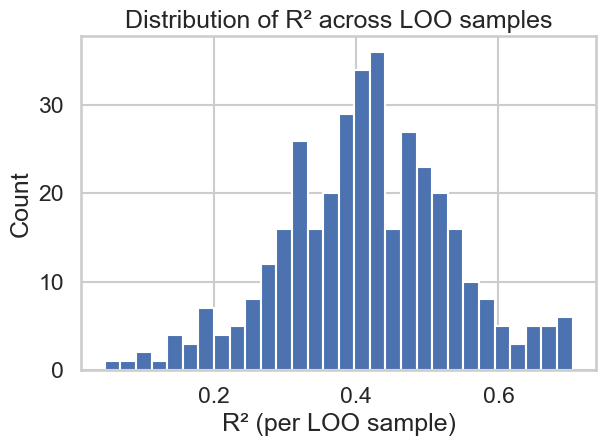


Top 10 LOO samples by R²:


,LOO sample,r2
254,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.704278
97,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.700002
294,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.698543
257,OCILY3_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.692568
41,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.691873
278,REH_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.684117
324,SUDHL4_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.678643
277,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.674108
349,TF1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.673761
284,RL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.672376



Bottom 10 LOO samples by R²:


,LOO sample,r2
279,RERFLCMS_LUNG,0.046397
213,NCIH1573_LUNG,0.081228
182,LXF289_LUNG,0.096189
235,NCIH2291_LUNG,0.099428
105,HS944T_SKIN,0.127715
272,PC3_PROSTATE,0.142488
286,RPMI7951_SKIN,0.143430
320,SNUC2A_LARGE_INTESTINE,0.147548
242,NCIH460_LUNG,0.155479
196,MKN1_STOMACH,0.156523


In [157]:


# Per-sample R² (across proteins within each LOO sample)
def _r2_sample_group(g):
    y, yhat = g['true'].values, g['predicted'].values
    return r2_score(y, yhat) if (len(y) > 1 and np.var(y) > 0) else np.nan

r2_by_sample = (combined_df
                .groupby('LOO sample', dropna=False)
                .apply(_r2_sample_group)
                .rename('r2')
                .reset_index())

print("R² by sample — summary:")
print(r2_by_sample['r2'].describe())

# Histogram
plt.figure()
plt.hist(r2_by_sample['r2'].dropna().values, bins=30)
plt.xlabel('R² (per LOO sample)')
plt.ylabel('Count')
plt.title('Distribution of R² across LOO samples')
plt.tight_layout()
plt.show()

# Optional: extremes
print("\nTop 10 LOO samples by R²:")
display(r2_by_sample.sort_values('r2', ascending=False).head(10))
print("\nBottom 10 LOO samples by R²:")
display(r2_by_sample.sort_values('r2', ascending=True).head(10))


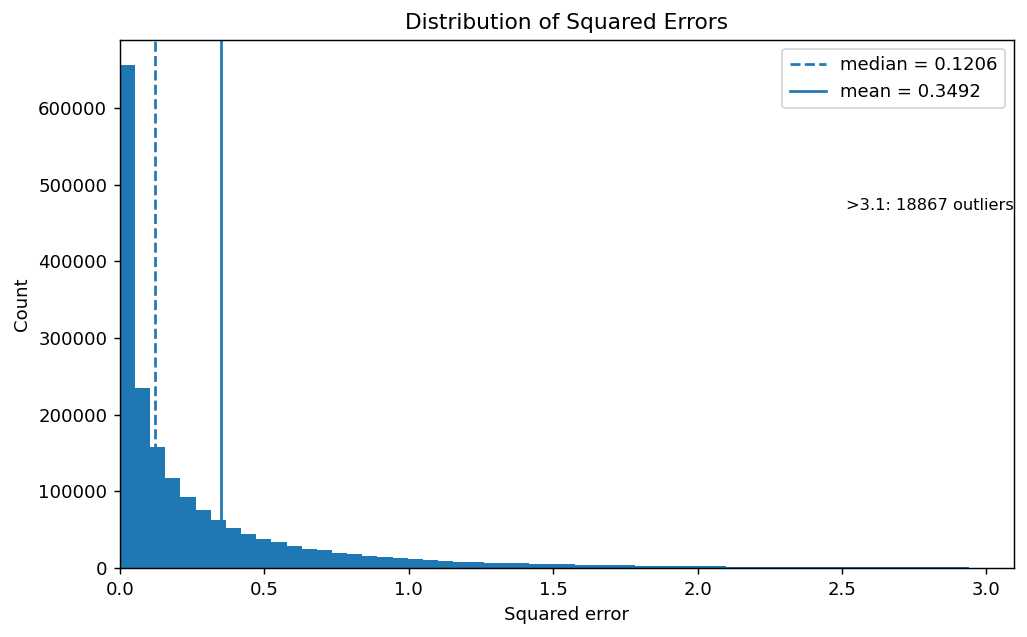

In [11]:
# pull clean squared errors
se = (pd.to_numeric(combined_df["squared_error"], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna())

# choose an x-axis cap (tweak if you like)
p95, p99, p999 = np.percentile(se, [95, 99, 99.9])
xmax = p99          # show up to the 99th percentile
tail_n = int((se > xmax).sum())

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

# histogram only for values within the cap
data_in = se[se <= xmax]
bins = np.linspace(0, xmax, 60)
ax.hist(data_in, bins=bins)

# annotate mean/median (only if they fall within the shown range)
mean_val = se.mean()
med_val  = se.median()
if med_val <= xmax:
    ax.axvline(med_val, linestyle="--", linewidth=1.5, label=f"median = {med_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.90, f"median = {med_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

if mean_val <= xmax:
    ax.axvline(mean_val, linestyle="-", linewidth=1.5, label=f"mean = {mean_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.80, f"mean = {mean_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

# x-axis limits and a note about the hidden tail
ax.set_xlim(0, xmax)
if tail_n > 0:
    ax.text(xmax, ax.get_ylim()[1]*0.70, f">{xmax:.3g}: {tail_n} outliers",
            ha="right", va="top", fontsize=9)

ax.set_title("Distribution of Squared Errors")
ax.set_xlabel("Squared error")
ax.set_ylabel("Count")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


In [74]:
# Per-sample metrics from combined_df → samples_df (369 rows expected)
eps = 1e-12

combined_df = combined_df.copy()

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# the column holding sample IDs (handles the space in "LOO sample")
sample_col = 'LOO sample' if 'LOO sample' in combined_df.columns else 'sample'

samples_df = (
    combined_df.groupby(sample_col, sort=False)
      .apply(lambda g: pd.Series({
          'n_proteins': len(g),
          'mae': g['abs_error'].mean(),
          'mse': g['squared_error'].mean(),
          'rmse': np.sqrt(g['squared_error'].mean()),
          'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
          'pearson_corr': g['true'].corr(g['predicted'])
      }))
      .reset_index()
      .rename(columns={sample_col: 'sample'})
)

samples_df.head()


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
0,MDAMB468_BREAST,5113.0,0.303867,0.167445,0.409201,0.663846,0.667621
1,SH4_SKIN,5113.0,0.292403,0.154867,0.393532,0.689430,0.689368
2,AU565_BREAST,5113.0,0.315198,0.171289,0.413871,0.741380,0.740429
3,KMRC1_KIDNEY,5113.0,0.311665,0.173821,0.416918,0.701520,0.694470
4,CAL51_BREAST,5113.0,0.283060,0.143828,0.379247,0.673707,0.676567


In [75]:
#  tissue counts from samples_df 

min_n = 18 # threshold for "low-representation" tissues

# Tissue is the suffix after the last underscore
samples_df = samples_df.copy()
samples_df["tissue"] = samples_df["sample"].astype(str).str.rsplit("_", n=1).str[-1]

# Count unique samples per tissue
tissue_counts = (
    samples_df.drop_duplicates("sample")
              .groupby("tissue")["sample"]
              .nunique()
              .sort_values()
)

low_tissues = tissue_counts[tissue_counts <= min_n]

print(f"Total tissues: {tissue_counts.size}")
print(f"Tissues with <= {min_n} samples:")
if low_tissues.empty:
    print("  (none)")
else:
    # pretty print as two columns
    print(low_tissues.to_string())


Total tissues: 19
Tissues with <= 18 samples:
tissue
GANGLIA         1
THYROID         2
PLEURA          2
PROSTATE        4
BONE            7
KIDNEY         11
SYSTEM         13
ENDOMETRIUM    14
LIVER          14
STOMACH        14
OESOPHAGUS     14
OVARY          17


In [76]:
#  filter combined_df by tissue representation 
n = 18  # set the threshold here

# Reuse tissue mapping from Cell 1 (samples_df already has a 'tissue' column)
tissue_sample_counts = (
    samples_df.drop_duplicates("sample")
              .groupby("tissue")["sample"]
              .nunique()
)

low_tissues = set(tissue_sample_counts[tissue_sample_counts < n].index)

# All samples that belong to low-representation tissues
low_tissue_samples = set(
    samples_df.loc[samples_df["tissue"].isin(low_tissues), "sample"].unique()
)

# combined_df may name the sample column as 'LOO_sample' or 'LOO sample'—we handle both.
sample_col = "LOO_sample" if "LOO_sample" in combined_df.columns else (
    "LOO sample" if "LOO sample" in combined_df.columns else "sample"
)

before = len(combined_df)
clean = combined_df.loc[~combined_df[sample_col].isin(low_tissue_samples)].copy()
after = len(clean)

print(f"Threshold n = {n}")
print(f"Low-representation tissues ({len(low_tissues)}): {sorted(low_tissues) if low_tissues else 'none'}")
print(f"Removed {before - after} rows; kept {after} rows.")


Threshold n = 18
Low-representation tissues (12): ['BONE', 'ENDOMETRIUM', 'GANGLIA', 'KIDNEY', 'LIVER', 'OESOPHAGUS', 'OVARY', 'PLEURA', 'PROSTATE', 'STOMACH', 'SYSTEM', 'THYROID']
Removed 577769 rows; kept 1308928 rows.


In [77]:
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

per_protein = (
    clean.groupby('protein', sort=False)
    .apply(lambda g: pd.Series({
        'n_samples': len(g),
        'mse': g['squared_error'].mean(),
        'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
        'pearson_corr': g['true'].corr(g['predicted'])
    }))
    .reset_index()
)

### Top 100 proteins by mean squared error-cosine similarity-pearson correlation

In [78]:
# Per-protein ranking tables: MAE, cosine similarity, Pearson correlation


top100_mae     = per_protein.sort_values('mse', ascending=True).head(100)         # lower is better
top100_cosine  = per_protein.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = per_protein.sort_values('pearson_corr', ascending=False).head(100)

print("Top 100 proteins by lowest MAE")
display(top100_mae)

print("\nTop 100 proteins by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 proteins by highest Pearson correlation")
display(top100_pearson)

Top 100 proteins by lowest MAE


,protein,n_samples,mse,cosine_similarity,pearson_corr
3340,PPP1CC,256.0,0.074858,0.378758,0.354187
3456,PSMC1,256.0,0.080788,0.361778,0.347902
1097,DDX1,256.0,0.081452,0.150786,0.150611
3012,PABPC4,256.0,0.090069,0.575301,0.574780
3486,PTBP1,256.0,0.090256,0.331363,0.325555
...,...,...,...,...,...
2979,ORC2,256.0,0.127358,0.399094,0.392357
2328,LUC7L3,256.0,0.127426,0.238050,0.237430
4640,TRA2B,256.0,0.127495,0.295612,0.294234
2953,NUPL1,256.0,0.128195,0.261116,0.231395



Top 100 proteins by highest cosine similarity


,protein,n_samples,mse,cosine_similarity,pearson_corr
1843,HCLS1,256.0,0.583458,0.910515,0.910832
2016,IGF2BP1,256.0,0.404639,0.908840,0.905525
433,BASP1,256.0,1.095364,0.904316,0.904304
1719,GNG12,256.0,0.515685,0.901784,0.899218
4526,TJP2,256.0,0.283432,0.895819,0.894218
...,...,...,...,...,...
2258,LIMCH1,256.0,0.543247,0.850451,0.850129
2211,LAMB1,256.0,0.549082,0.850356,0.843528
685,CD44,256.0,0.666828,0.850082,0.850150
4246,SPINT1,256.0,0.842752,0.849979,0.851789



Top 100 proteins by highest Pearson correlation


,protein,n_samples,mse,cosine_similarity,pearson_corr
1843,HCLS1,256.0,0.583458,0.910515,0.910832
2016,IGF2BP1,256.0,0.404639,0.908840,0.905525
433,BASP1,256.0,1.095364,0.904316,0.904304
1719,GNG12,256.0,0.515685,0.901784,0.899218
924,CORO1A,256.0,0.624798,0.893110,0.894506
...,...,...,...,...,...
220,ANXA6,256.0,0.611546,0.850634,0.849075
1537,FERMT3,256.0,0.671510,0.843999,0.848225
1404,ERBB2,256.0,0.422558,0.849435,0.847896
3898,S100A14,256.0,1.445372,0.847914,0.847896


In [79]:
# Intersection
set_mae  = set(top100_mae['protein'])
set_cos  = set(top100_cosine['protein'])
set_pear = set(top100_pearson['protein'])
inter_prots = sorted(set_mae & set_cos & set_pear)

print(f"Proteins in the intersection of all three top-100 lists: {len(inter_prots)}")

if len(inter_prots) == 0:
    print("No overlap across the three lists.")
else:
    # Add ranks for context
    pp_idx = per_protein.set_index('protein')
    ranked = pp_idx.assign(
        mae_rank=pp_idx['mae'].rank(method='min', ascending=True).astype(int),
        cosine_rank=pp_idx['cosine_similarity'].rank(method='min', ascending=False).astype(int),
        pearson_rank=pp_idx['pearson_corr'].rank(method='min', ascending=False).astype(int),
    )

    intersection_table = (
        ranked.loc[inter_prots, ['n_samples', 'mae', 'mae_rank',
                                 'cosine_similarity', 'cosine_rank',
                                 'pearson_corr', 'pearson_rank']]
        .sort_values(['mae', 'cosine_rank', 'pearson_rank'])
        .reset_index()
        .rename(columns={'protein': 'protein'})
    )

    display(intersection_table)

Proteins in the intersection of all three top-100 lists: 0
No overlap across the three lists.


### Error Distributions and thresholds 

#### means

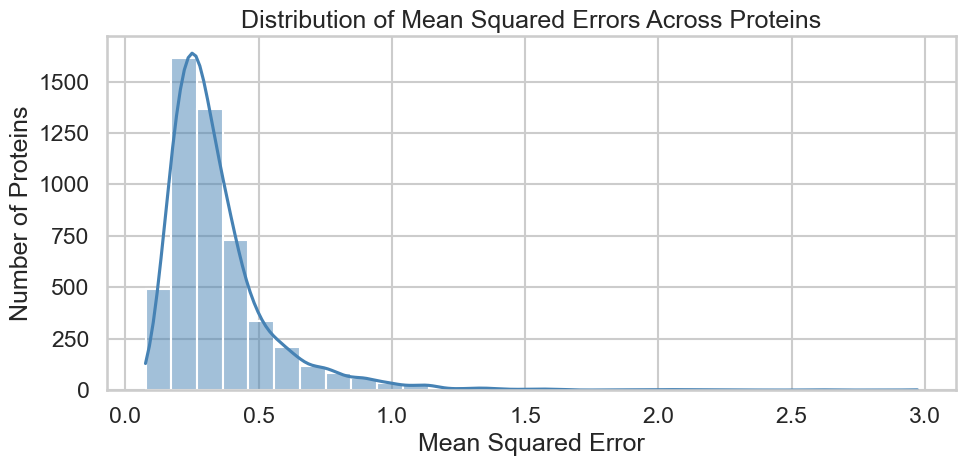

In [80]:
# Compute mean squared error for each protein across samples
protein_means = combined_df.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Squared Errors Across Proteins")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

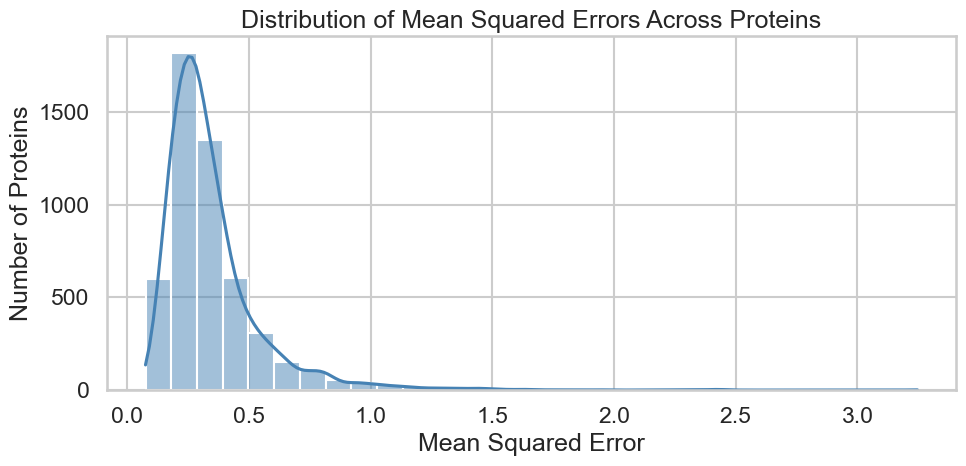

In [81]:
# Compute mean squared error for each protein across samples
protein_means = clean.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Squared Errors Across Proteins")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with mean_squared_error < 0.1: 16


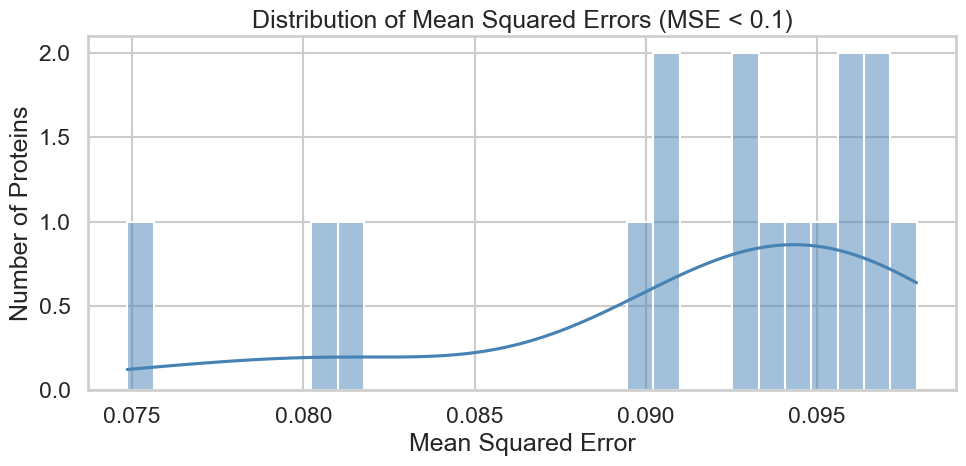


Table: Proteins with MSE < 0.100 (sorted ascending)


,protein,mean_squared_error
0,PPP1CC,0.074858
1,PSMC1,0.080788
2,DDX1,0.081452
3,PABPC4,0.090069
4,PTBP1,0.090256
5,PSMC6,0.090734
6,DDX3X,0.092923
7,PTBP3,0.093097
8,PSMC5,0.093595
9,YTHDF3,0.094579


In [82]:
# MAE < 0.1
threshold = 0.1

# mask + subset for plotting
mask = protein_means["mean_squared_error"] < threshold
subset = protein_means.loc[mask, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_means.columns:
        table = protein_means.loc[mask, ["protein", "mean_squared_error"]].copy()
    else:
        table = (
            protein_means.loc[mask, ["mean_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("mean_squared_error").reset_index(drop=True)
    table["mean_squared_error"] = table["mean_squared_error"].astype(float)

    # Display nicely in notebooks (falls back to print if display isn't available)
    try:
        from IPython.display import display
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Proteins with mean_squared_error < 0.2: 878


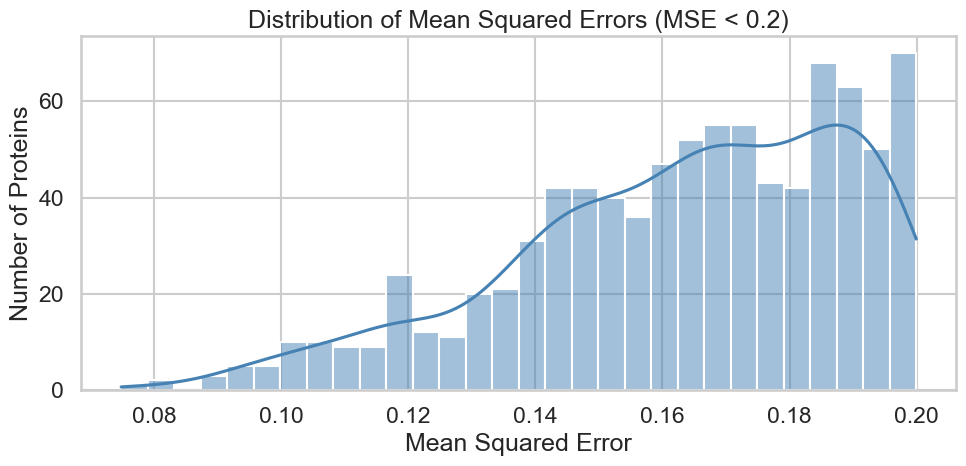

In [83]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.2)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 2636


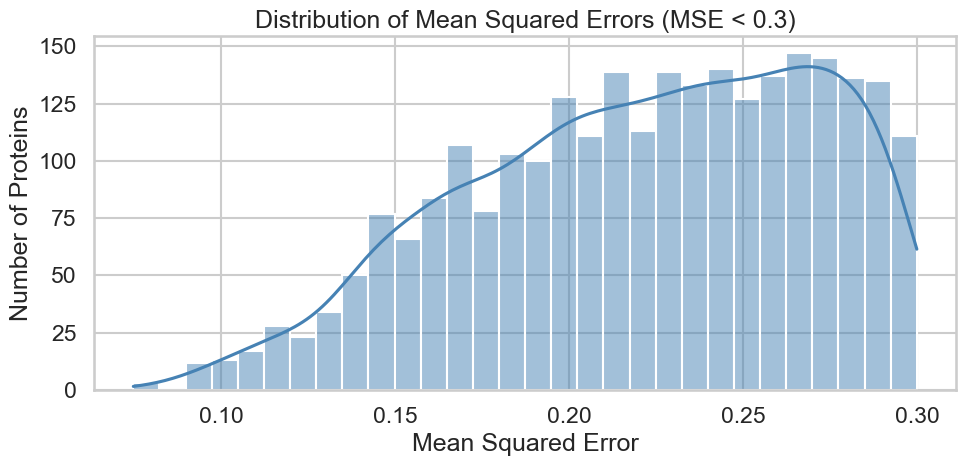

In [84]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


#### medians

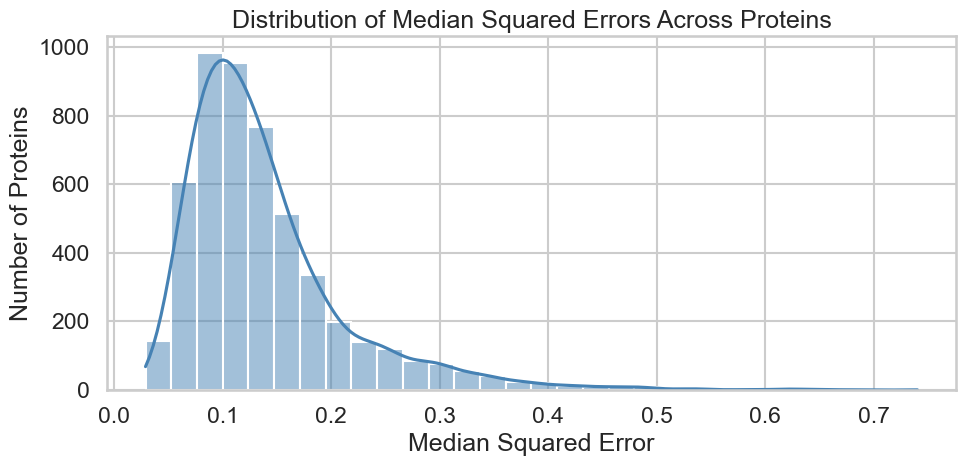

In [85]:
# Compute median squared error for each protein across samples
protein_medians = combined_df.groupby("protein")["squared_error"].median().reset_index()
protein_medians.rename(columns={"squared_error": "median_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians["median_squared_error"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Median Squared Errors Across Proteins")
plt.xlabel("Median Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with median_squared_error < 0.05: 111


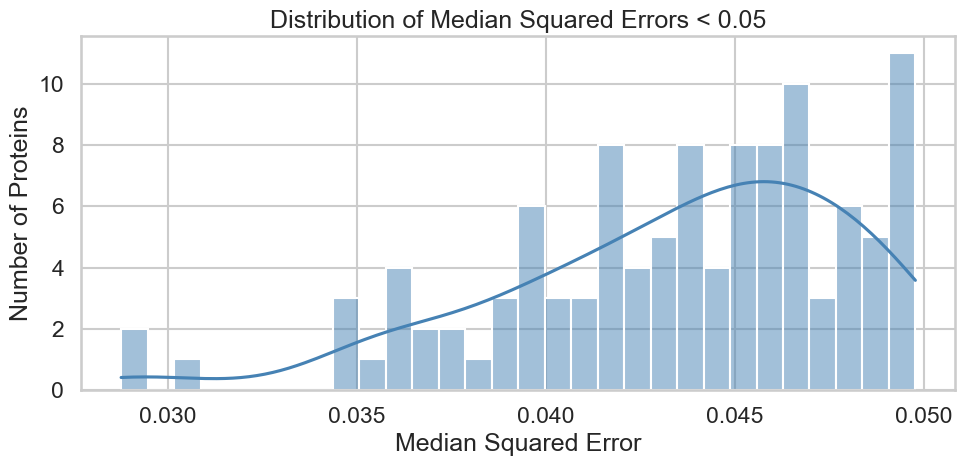


Table: Proteins with Median Squared Error < 0.050 (sorted ascending)


,protein,median_squared_error
0,PSMC6,0.028763
1,PPP1CC,0.028823
2,DYNLL1,0.030423
3,PTBP3,0.034456
4,POLR2B,0.034824
5,PSMC1,0.034846
6,PPP1CB,0.035375
7,RPL11,0.035837
8,PSMC4,0.035914
9,PUM1,0.036193


In [86]:
# MAE < 0.1
threshold = 0.05

# mask + subset for plotting
mask = protein_medians["median_squared_error"] < threshold
subset = protein_medians.loc[mask, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Median Squared Errors < {threshold}")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_medians.columns:
        table = protein_medians.loc[mask, ["protein", "median_squared_error"]].copy()
    else:
        table = (
            protein_medians.loc[mask, ["median_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("median_squared_error").reset_index(drop=True)
    table["median_squared_error"] = table["median_squared_error"].astype(float)

    # Display nicely in notebooks (falls back to print if display isn't available)
    try:
        from IPython.display import display
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))

Proteins with median_squared_error < 0.1: 1736


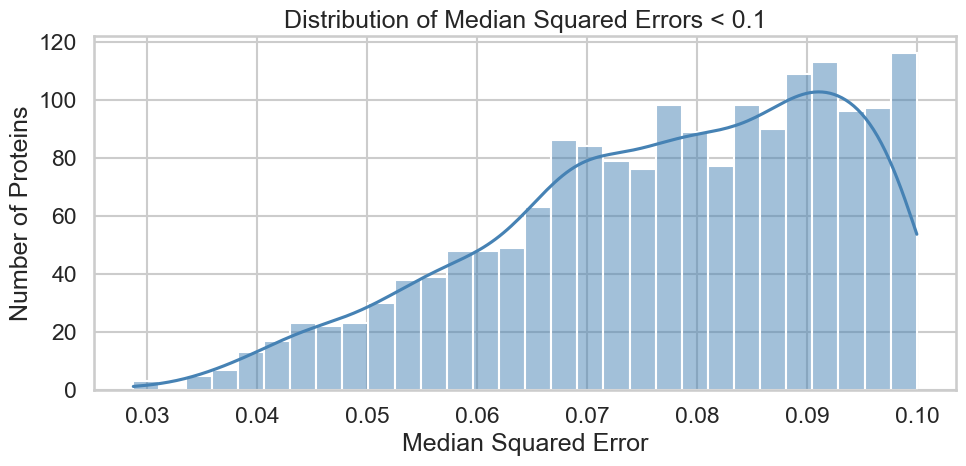


Table: Proteins with Median Squared Error < 0.100 (sorted ascending)


,protein,median_squared_error
0,PSMC6,0.028763
1,PPP1CC,0.028823
2,DYNLL1,0.030423
3,PTBP3,0.034456
4,POLR2B,0.034824
5,PSMC1,0.034846
6,PPP1CB,0.035375
7,RPL11,0.035837
8,PSMC4,0.035914
9,PUM1,0.036193


In [87]:
# MAE < 0.1
threshold = 0.1

# mask + subset for plotting
mask = protein_medians["median_squared_error"] < threshold
subset = protein_medians.loc[mask, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Median Squared Errors < {threshold}")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_medians.columns:
        table = protein_medians.loc[mask, ["protein", "median_squared_error"]].copy()
    else:
        table = (
            protein_medians.loc[mask, ["median_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("median_squared_error").reset_index(drop=True)
    table["median_squared_error"] = table["median_squared_error"].astype(float)

    # Display nicely in notebooks (falls back to print if display isn't available)
    try:
        from IPython.display import display
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


In [88]:
enet01 = set(list(table['protein']))
print(len(enet01))

1736


In [89]:
enet01

{'ATXN2L',
 'EXOSC3',
 'PUF60',
 'TRA2B',
 'LETM1',
 'COG6',
 'TSSC4',
 'MRPS23',
 'COPS8',
 'SMARCC2',
 'HUWE1',
 'GNB4',
 'POLR3F',
 'PIP4K2C',
 'SLC25A6',
 'GTF3C3',
 'VMA21',
 'SNRPB',
 'LSM12',
 'USP16',
 'NUP205',
 'PIK3R4',
 'GGA3',
 'MESDC2',
 'ARPC4',
 'CC2D1A',
 'TXNL4A',
 'UBA3',
 'NFRKB',
 'KAT8',
 'PSME3',
 'RPTOR',
 'DDX39B',
 'DCTN1',
 'SFPQ',
 'UPF2',
 'ANAPC2',
 'MFN2',
 'PRKAG1',
 'PIK3C3',
 'YME1L1',
 'SNX15',
 'RAD23B',
 'OFD1',
 'ARID4B',
 'ASUN',
 'BTAF1',
 'YTHDF2',
 'HEATR1',
 'RABGEF1',
 'TMED4',
 'RPL10',
 'ORC2',
 'KIAA1033',
 'ZNF207',
 'UBR5',
 'PPIB',
 'DDX6',
 'LAMTOR2',
 'SLC25A20',
 'PLXNA1',
 'HIF1AN',
 'GPKOW',
 'NCBP1',
 'RAB21',
 'YTHDF1',
 'PAF1',
 'MORC3',
 'DCTN6',
 'PHF8',
 'RDH14',
 'RPL8',
 'BIRC6',
 'COPS6',
 'TUFM',
 'SETDB1',
 'PRR12',
 'RBM17',
 'ELAVL1',
 'DCP1A',
 'RPS26',
 'ARMC1',
 'XRCC6',
 'NFS1',
 'GNAS',
 'MRPS34',
 'SNRPA',
 'RRP1B',
 'CKAP5',
 'MED1',
 'POLR1B',
 'TSC2',
 'RFC5',
 'RPP30',
 'WDFY1',
 'FAM98A',
 'RPS7',
 'CXorf56'

In [90]:
csv_df = pd.read_csv('res_data/proteins01.csv')
xgb01 = set(list(csv_df['protein']))
print(len(xgb01))

1643


In [91]:
len(enet01 & xgb01)

1282

In [92]:
len(enet01 | xgb01)

2097

Proteins with median_squared_error < 0.2: 4348


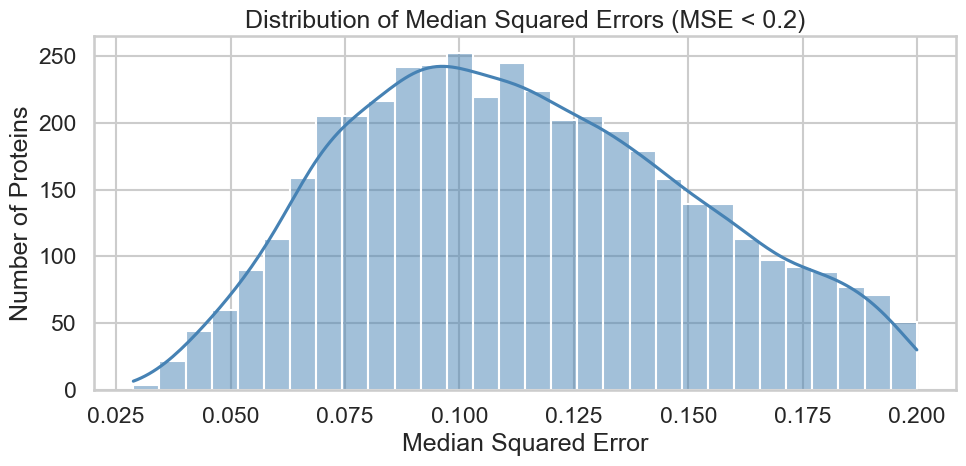

In [93]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_medians.loc[protein_medians["median_squared_error"] < threshold, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Median Squared Errors (MSE < 0.2)")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

Proteins with median_squared_error < 0.3: 4879


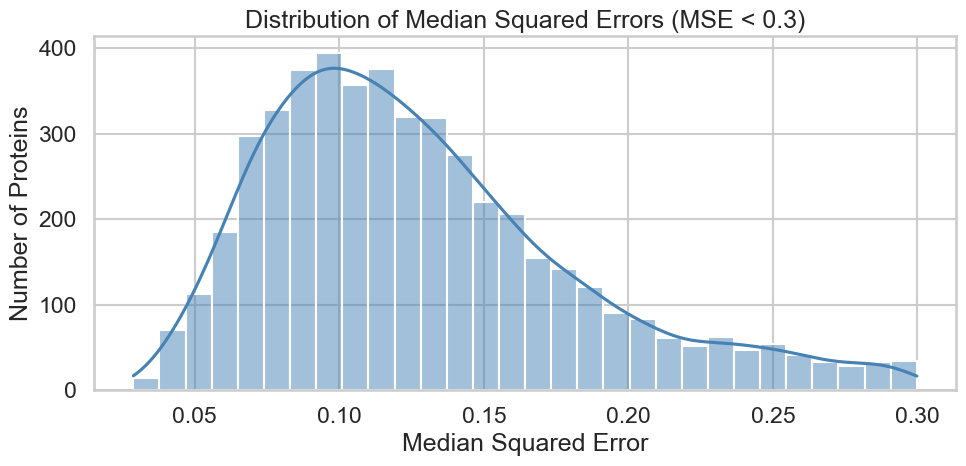

In [94]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_medians.loc[protein_medians["median_squared_error"] < threshold, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Median Squared Errors (MSE < 0.3)")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


### Other per-protein plots

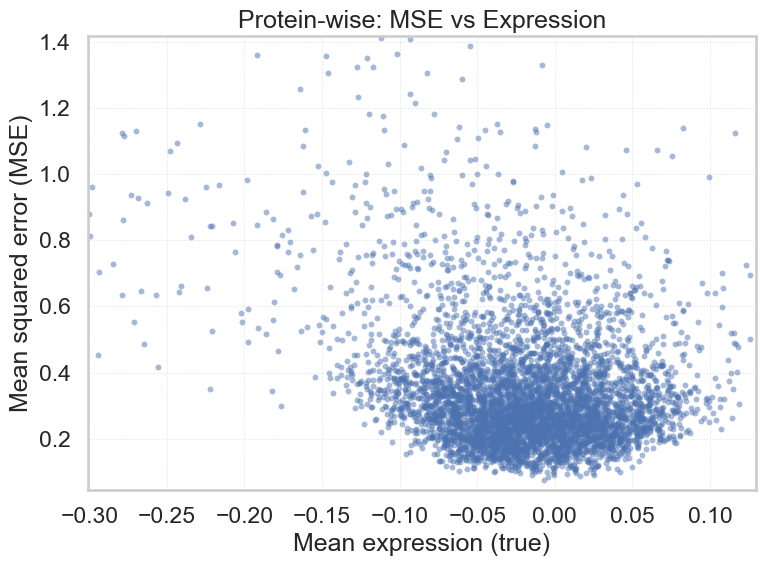

In [162]:
# MSE vs expression with robust limits and readable 1:1 line

# Recompute per-protein summary (safe if it already exists)
prot_perf = (
    combined_df.groupby('protein')
    .agg(expression=('true', 'mean'),
         mse=('squared_error', 'mean'),
         mae=('abs_error', 'mean'))
    .reset_index()
)

x = prot_perf['expression'].to_numpy()
y = prot_perf['mse'].to_numpy()

# Robust axis limits (clip to 0.5–99.5 percentiles and pad 5%)
x_lo, x_hi = np.nanpercentile(x, [0.5, 99.5])
y_lo, y_hi = np.nanpercentile(y, [0.5, 99.5])
x_pad = 0.05 * (x_hi - x_lo) if np.isfinite(x_hi - x_lo) else 1.0
y_pad = 0.05 * (y_hi - y_lo) if np.isfinite(y_hi - y_lo) else 1.0
xlim = (x_lo - x_pad, x_hi + x_pad)
ylim = (y_lo - y_pad, y_hi + y_pad)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_perf, x='expression', y='mse',
    s=18, alpha=0.5, linewidth=0, edgecolor=None
)


plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression')
plt.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)
plt.tight_layout()
plt.show()


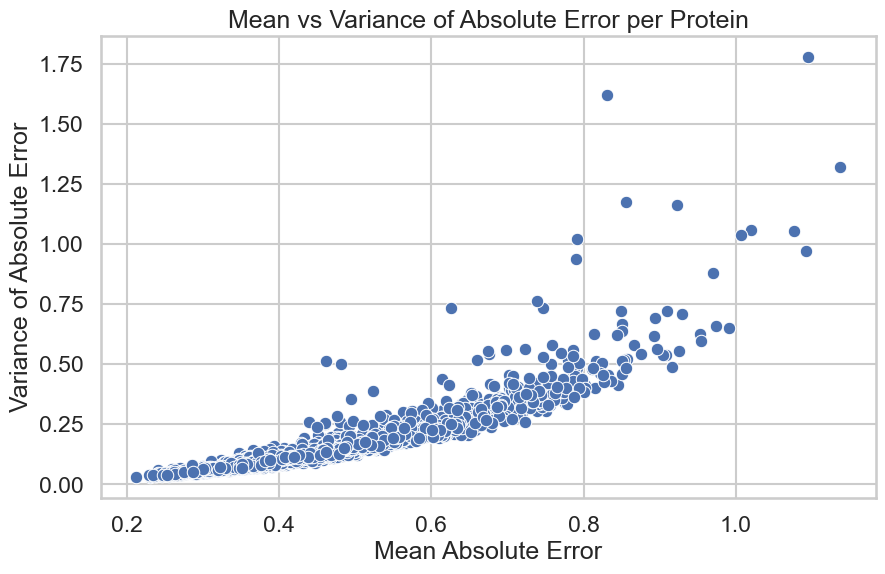

In [96]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

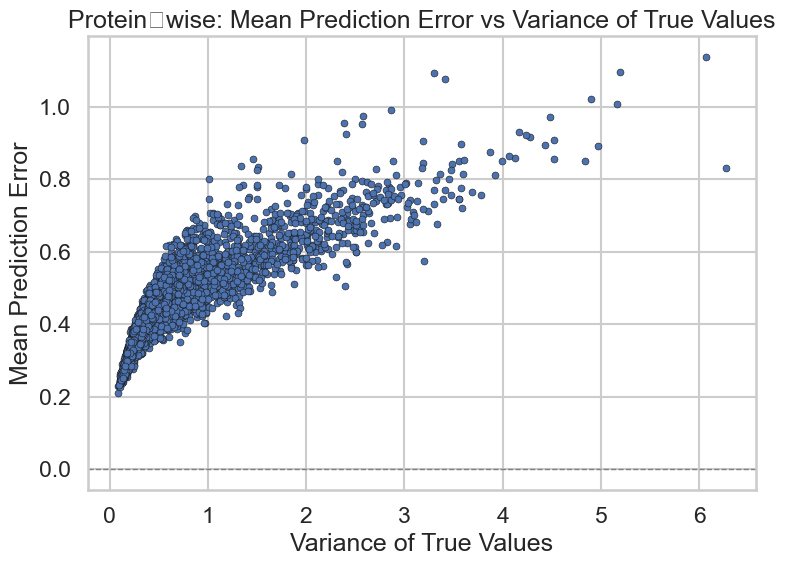

In [97]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Cosine similaity 

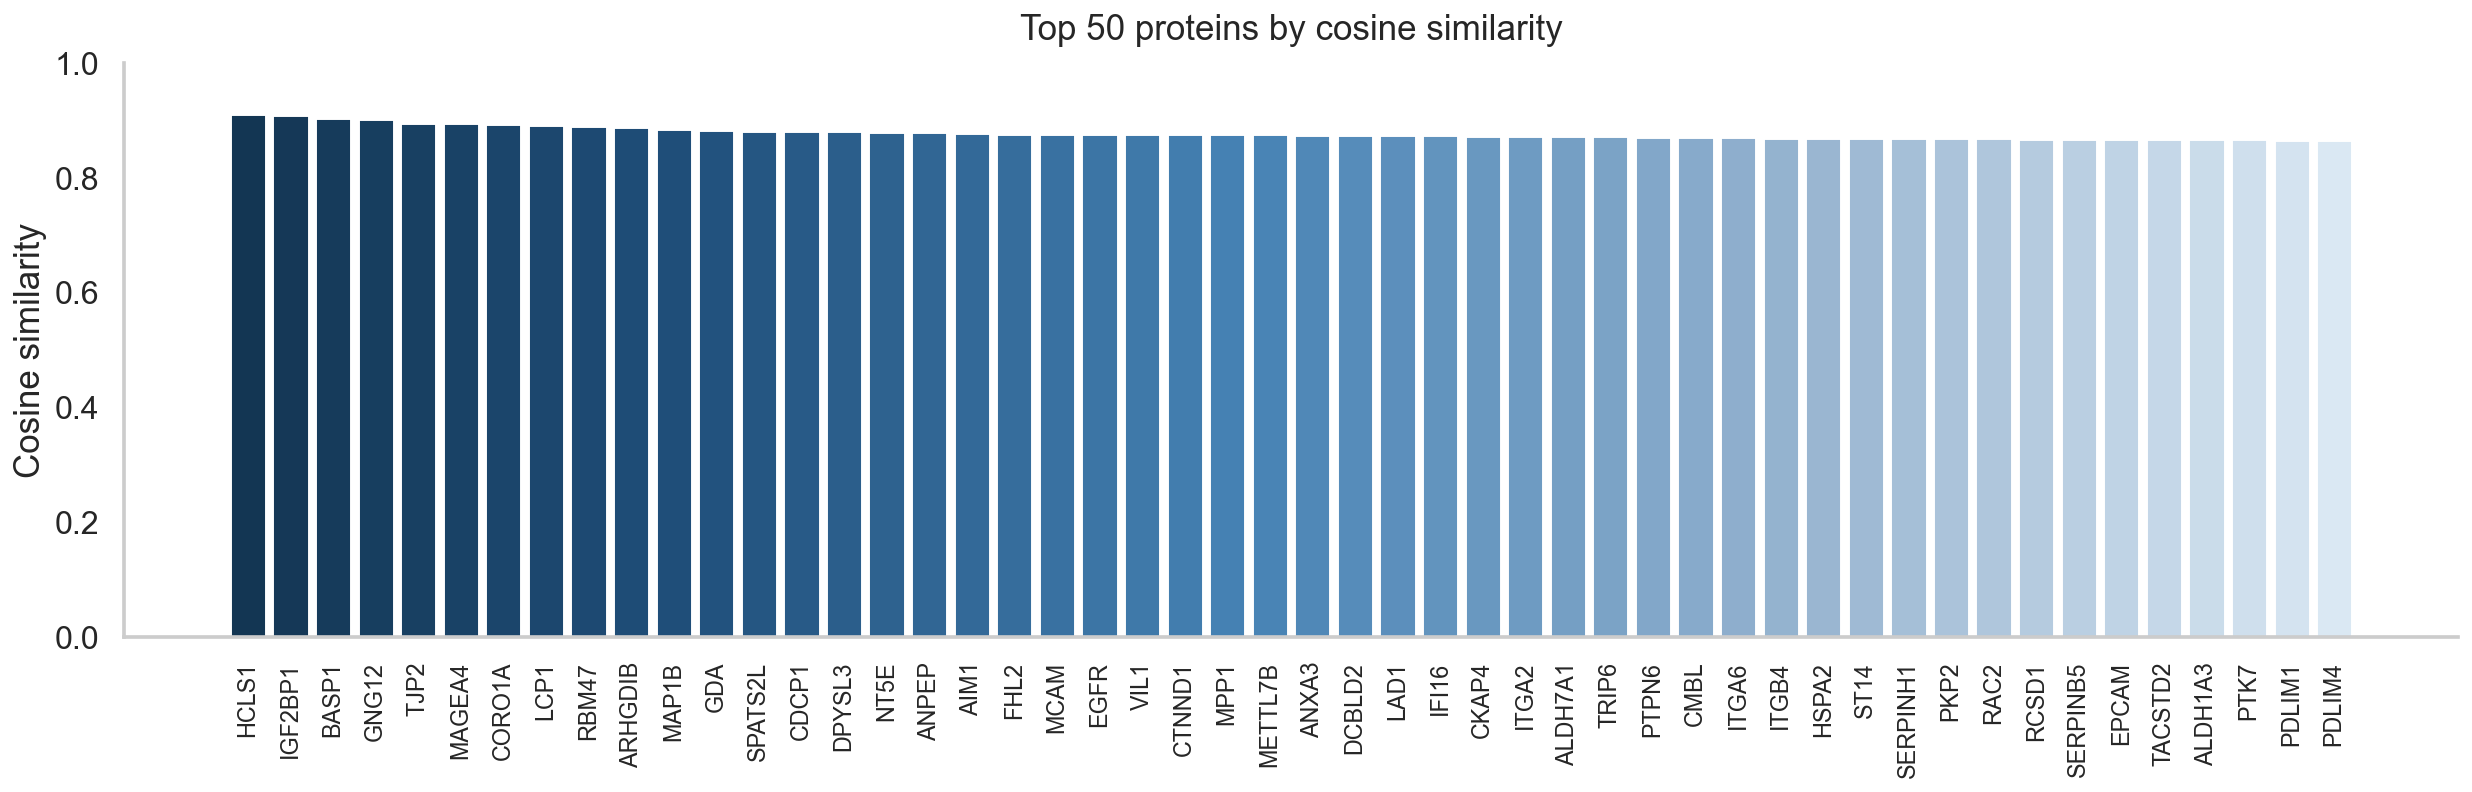

In [98]:
# Top 50, vertical bars, steelblue gradient
# prep
df = per_protein.copy()
if 'protein' in df.columns:
    df = df.set_index('protein')

df_top = (
    df[['cosine_similarity']]
    .dropna()
    .sort_values('cosine_similarity', ascending=False)
    .head(50)
)

vals   = df_top['cosine_similarity'].to_numpy()
labels = df_top.index.astype(str)

# custom steelblue gradient (deep navy → steelblue → pale)
steelblue_cmap = LinearSegmentedColormap.from_list(
    "steelblue_ramp",
    ["#0f2d45", "#1f4e79", "#4682B4", "#9ab6d1", "#e2eef7"]
)

# color by rank so the gradient flows left→right
colors = steelblue_cmap(np.linspace(0.07, 0.97, len(vals)))

fig, ax = plt.subplots(figsize=(18, 6), dpi=140)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85)

# labels & limits
ax.set_title('Top 50 proteins by cosine similarity', pad=12)
ax.set_ylabel('Cosine similarity')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=12)
ax.set_ylim(0, max(1.0, vals.max() + 0.05))

# subtle grid & cleanup
ax.grid(False, which='both')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


How many prteins after applying cosine similarity threshold of 0.5, 0.6, 0.7, 0.8, 0.9

In [99]:
# Summary table for cosine similarity thresholds + save per-threshold protein lists

from datetime import datetime

df = per_protein.copy()
if 'protein' in df.columns:
    df = df.set_index('protein')

# restrict to non-null cosine similarities
cs = df['cosine_similarity'].dropna()
total = int(cs.shape[0])

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []

# prepare output dir + timestamp
out_dir = Path("exports")
out_dir.mkdir(parents=True, exist_ok=True)
stamp = datetime.now().strftime("%Y%m%d-%H%M%S")

for t in thresholds:
    mask = cs > t
    n = int(mask.sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

    # build table for proteins above this threshold
    tbl = (
        df.loc[mask, ["cosine_similarity"]]
          .sort_values("cosine_similarity", ascending=False)
          .assign(protein=lambda d: d.index)
          .loc[:, ["protein", "cosine_similarity"]]
    )

    # save CSV (empty files will still be created with headers)
    fname = out_dir / f"proteins_cosine_similarity_gt_{str(t).replace('.', 'p')}_{stamp}.csv"
    tbl.to_csv(fname, index=False)
    print(f"Saved {n} proteins with cosine_similarity > {t:.1f} -> {fname.resolve()}")

summary = pd.DataFrame(rows).set_index("threshold")

print(f"\nTotal proteins considered: {total}\n")
print(summary.to_string())


Saved 2842 proteins with cosine_similarity > 0.5 -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\exports\proteins_cosine_similarity_gt_0p5_20251113-132105.csv
Saved 1912 proteins with cosine_similarity > 0.6 -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\exports\proteins_cosine_similarity_gt_0p6_20251113-132105.csv
Saved 1088 proteins with cosine_similarity > 0.7 -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\exports\proteins_cosine_similarity_gt_0p7_20251113-132105.csv
Saved 390 proteins with cosine_similarity > 0.8 -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\exports\proteins_cosine_similarity_gt_0p8_20251113-132105.csv

Total proteins considered: 5113

           n_proteins % of total
threshold                       
>0.5             2842      55.6%
>0.6             1912      37.4%
>0.7             1088      21.3%
>0.8              

In [100]:
#positive 
pos = df[df['cosine_similarity'] > 0]
len(pos)

5099

In [101]:


# total rows considered (robust to NaNs)
total = int(pos['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((pos['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total proteins considered: {total}\n")
print(summary.to_string())


Total proteins considered: 5099

           n_proteins % of total
threshold                       
>0.5             2842      55.7%
>0.6             1912      37.5%
>0.7             1088      21.3%
>0.8              390       7.6%


In [102]:
df[['cosine_similarity']].describe()

,cosine_similarity
count,5113.000000
mean,0.527524
std,0.187907
min,-0.239794
25%,0.390334
50%,0.527092
75%,0.676220
max,0.910515


### Comparison with baseline #to do

In [103]:
s = pd.read_csv("res_data/pe85.csv", dtype=str)["id"]   # Series
pe85 = s.tolist()                        # list

# Samples analysis


### Top 100 samples by mean squared error, cosine similarity, pearson correlation

In [129]:
# Per-sample metrics from combined_df → samples_df (369 rows expected)
eps = 1e-12

combined_df = combined_df.copy()

# row-wise errors
combined_df['abs_error']     = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# the column holding sample IDs (handles the space in "LOO sample")
sample_col = 'LOO sample' if 'LOO sample' in combined_df.columns else 'sample'

samples_df = (
    combined_df.groupby(sample_col, sort=False)
      .apply(lambda g: pd.Series({
          'n_proteins': len(g),
          'mae': g['abs_error'].mean(),
          'mse': g['squared_error'].mean(),
          'rmse': np.sqrt(g['squared_error'].mean()),
          'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
          'pearson_corr': g['true'].corr(g['predicted'])
      }))
      .reset_index()
      .rename(columns={sample_col: 'sample'})
)

samples_df.head()


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
0,MDAMB468_BREAST,5113.0,0.303867,0.167445,0.409201,0.663846,0.667621
1,SH4_SKIN,5113.0,0.292403,0.154867,0.393532,0.689430,0.689368
2,AU565_BREAST,5113.0,0.315198,0.171289,0.413871,0.741380,0.740429
3,KMRC1_KIDNEY,5113.0,0.311665,0.173821,0.416918,0.701520,0.694470
4,CAL51_BREAST,5113.0,0.283060,0.143828,0.379247,0.673707,0.676567


### Top 100 proteins by mean squared error, cosine similarity, pearson correlation

In [130]:

top100_mse     = samples_df.sort_values('mse', ascending=True).head(100)               # lower is better
top100_mae     = samples_df.sort_values('mae', ascending=True).head(100)               # optional: also show by MAE
top100_cosine  = samples_df.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = samples_df.sort_values('pearson_corr',       ascending=False).head(100)

print("Top 100 samples by lowest MSE")
display(top100_mse)

print("\nTop 100 samples by lowest MAE")
display(top100_mae)

print("\nTop 100 samples by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 samples by highest Pearson correlation")
display(top100_pearson)


Top 100 samples by lowest MSE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
22,A2058_SKIN,5113.0,0.233064,0.097085,0.311585,0.715292,0.715013
23,SW620_LARGE_INTESTINE,5113.0,0.260827,0.119574,0.345794,0.668209,0.674276
21,A375_SKIN,5113.0,0.278190,0.128660,0.358692,0.652054,0.653294
18,JIMT1_BREAST,5113.0,0.272037,0.132232,0.363637,0.693461,0.696024
17,PATU8988T_PANCREAS,5113.0,0.277002,0.132638,0.364194,0.642010,0.662279
...,...,...,...,...,...,...,...
82,HCC95_LUNG,5113.0,0.374013,0.258882,0.508804,0.575970,0.581958
278,HS944T_SKIN,5113.0,0.379539,0.260319,0.510215,0.461822,0.478264
317,SW1417_LARGE_INTESTINE,5113.0,0.367718,0.260328,0.510223,0.722032,0.724237
164,LN229_CENTRAL_NERVOUS_SYSTEM,5113.0,0.367654,0.261780,0.511645,0.772035,0.773628



Top 100 samples by lowest MAE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
22,A2058_SKIN,5113.0,0.233064,0.097085,0.311585,0.715292,0.715013
23,SW620_LARGE_INTESTINE,5113.0,0.260827,0.119574,0.345794,0.668209,0.674276
14,HS294T_SKIN,5113.0,0.265972,0.133627,0.365551,0.683369,0.673852
18,JIMT1_BREAST,5113.0,0.272037,0.132232,0.363637,0.693461,0.696024
11,SKHEP1_LIVER,5113.0,0.276271,0.138181,0.371727,0.694656,0.698691
...,...,...,...,...,...,...,...
278,HS944T_SKIN,5113.0,0.379539,0.260319,0.510215,0.461822,0.478264
67,PC3_PROSTATE,5113.0,0.382654,0.262299,0.512152,0.452755,0.467791
342,769P_KIDNEY,5113.0,0.382869,0.271616,0.521168,0.743420,0.769340
244,MSTO211H_PLEURA,5113.0,0.382946,0.243621,0.493579,0.697279,0.706160



Top 100 samples by highest cosine similarity


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.453939,0.355779,0.596472,0.857569,0.861113
219,OCILY3_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.466477,0.387380,0.622399,0.857549,0.853181
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.499205,0.463647,0.680916,0.853806,0.851813
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.435589,0.304355,0.551684,0.849703,0.851200
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.421867,0.309728,0.556532,0.840152,0.841333
...,...,...,...,...,...,...,...
237,NCIH446_LUNG,5113.0,0.359791,0.234552,0.484306,0.716599,0.717410
83,LK2_LUNG,5113.0,0.373417,0.235297,0.485075,0.715888,0.719186
22,A2058_SKIN,5113.0,0.233064,0.097085,0.311585,0.715292,0.715013
150,EFM19_BREAST,5113.0,0.435204,0.321520,0.567027,0.714520,0.743852



Top 100 samples by highest Pearson correlation


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.453939,0.355779,0.596472,0.857569,0.861113
219,OCILY3_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.466477,0.387380,0.622399,0.857549,0.853181
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.499205,0.463647,0.680916,0.853806,0.851813
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.435589,0.304355,0.551684,0.849703,0.851200
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.421867,0.309728,0.556532,0.840152,0.841333
...,...,...,...,...,...,...,...
93,HCC1500_BREAST,5113.0,0.508351,0.451542,0.671968,0.730060,0.730168
345,K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,5113.0,0.471390,0.391972,0.626077,0.729991,0.729599
177,SNU719_STOMACH,5113.0,0.464290,0.384978,0.620466,0.729567,0.729575
332,SW1783_CENTRAL_NERVOUS_SYSTEM,5113.0,0.405901,0.272640,0.522149,0.721237,0.727539


In [131]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.920625,0.610738,1.220479,1.455291,5113
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.767843,0.582728,0.929088,1.412112,5113
KNS81_CENTRAL_NERVOUS_SYSTEM,0.722669,0.540907,0.814773,1.251792,5113
NCIH1573_LUNG,0.699855,0.581263,0.827597,1.407798,5113
IM95_STOMACH,0.698584,0.537699,0.777084,2.054422,5113


### MSE thresholding and distributions

#### means

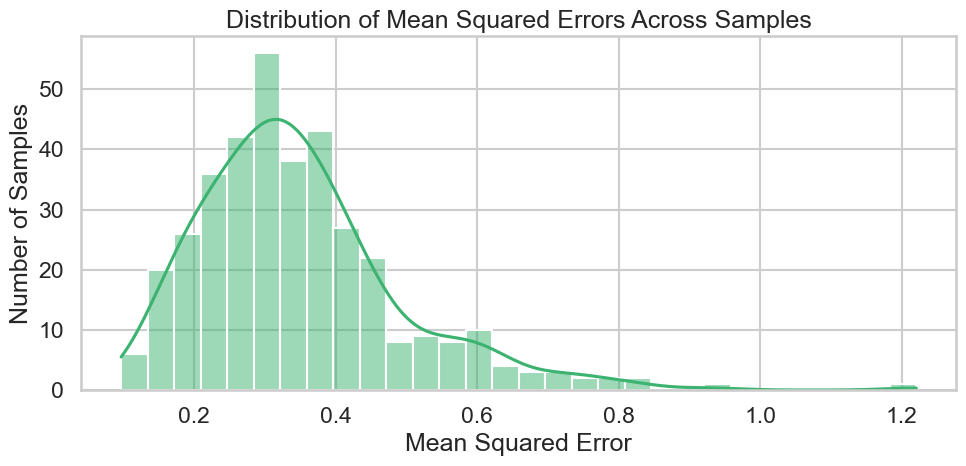

In [132]:
# Compute median absolute error across proteins for each sample
sample_means = combined_df.groupby("LOO sample")["squared_error"].mean().reset_index()
sample_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_means["mean_squared_error"], bins=30, kde=True, color="mediumseagreen")
plt.title("Distribution of Mean Squared Errors Across Samples")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


Samples with mean_squared_error < 0.1: 1


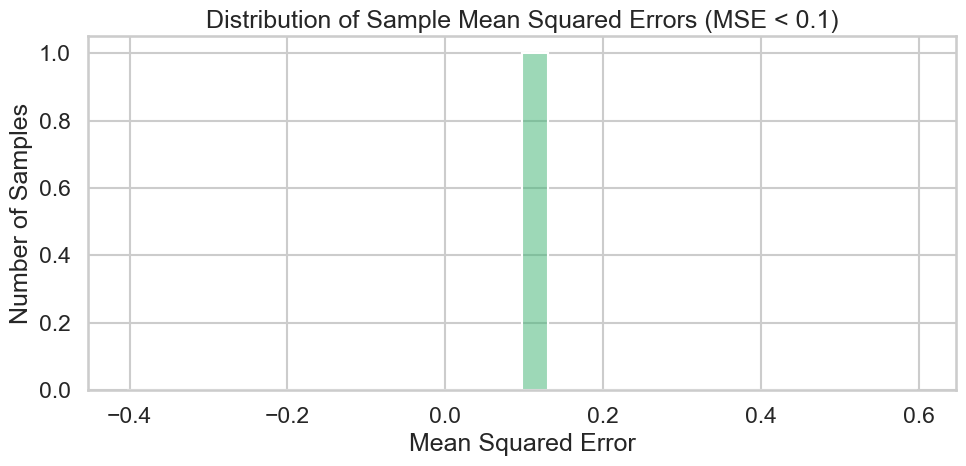


Table: Samples with MSE < 0.100 (sorted ascending)


,sample,mean_squared_error
0,A2058_SKIN,0.097085


In [133]:
# Mean Squared Error per sample + threshold plot (< 0.1)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

# mean squared error across proteins for each sample
sample_means = (
    combined_df.groupby(sample_col)["squared_error"]
               .mean()
               .reset_index()
               .rename(columns={sample_col: "sample", "squared_error": "mean_squared_error"})
)

threshold = 0.1

# mask + subset for plotting
mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.2: 46


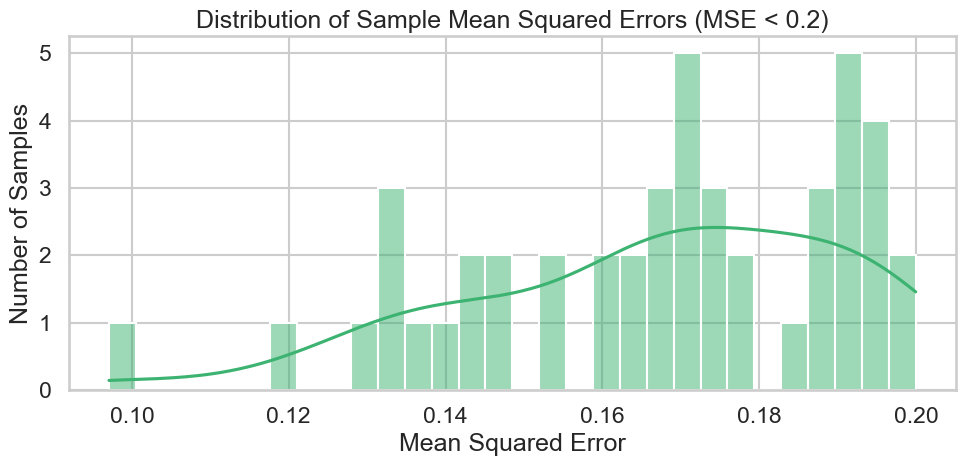


Table: Samples with MSE < 0.200 (sorted ascending)


In [134]:
threshold = 0.2

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.3: 143


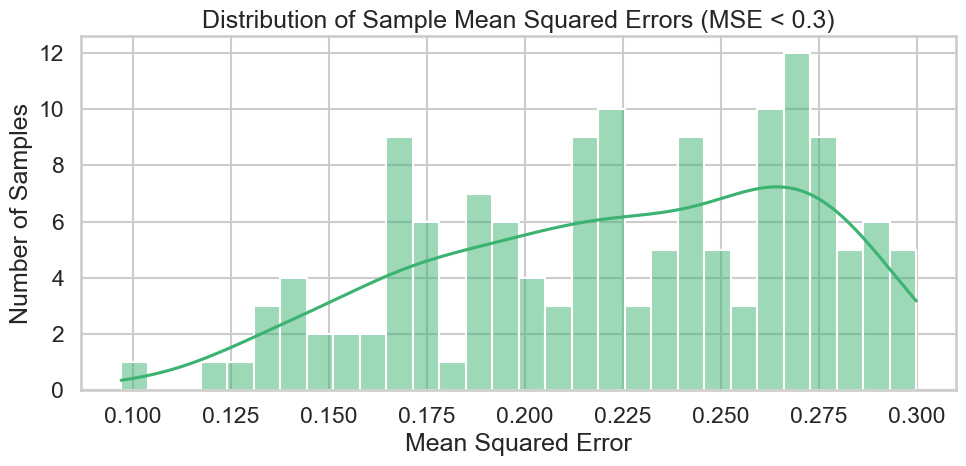


Table: Samples with MSE < 0.300 (sorted ascending)


In [135]:
threshold = 0.3

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


#### Medians

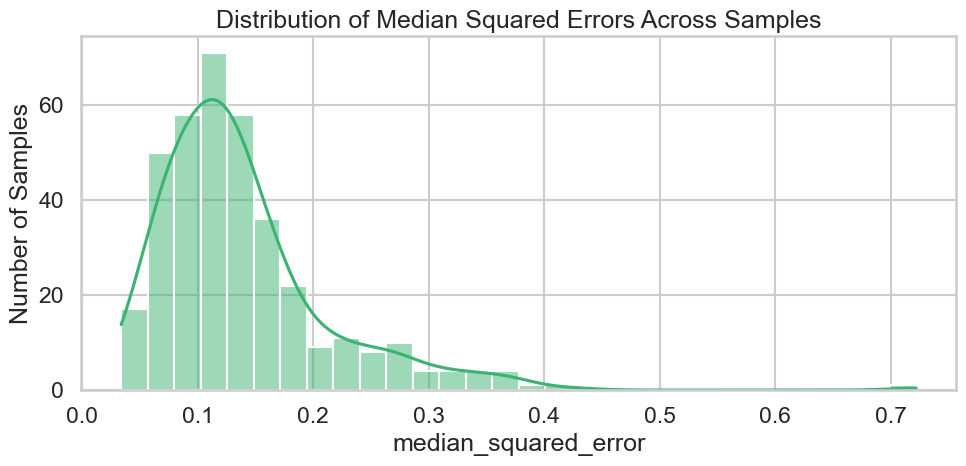

In [136]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["squared_error"].median().reset_index()
sample_medians.rename(columns={"squared_error": "median_squared_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_squared_error"], bins=30, kde=True, color="mediumseagreen")
plt.title("Distribution of Median Squared Errors Across Samples")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


Samples with median_squared_error < 0.05: 10


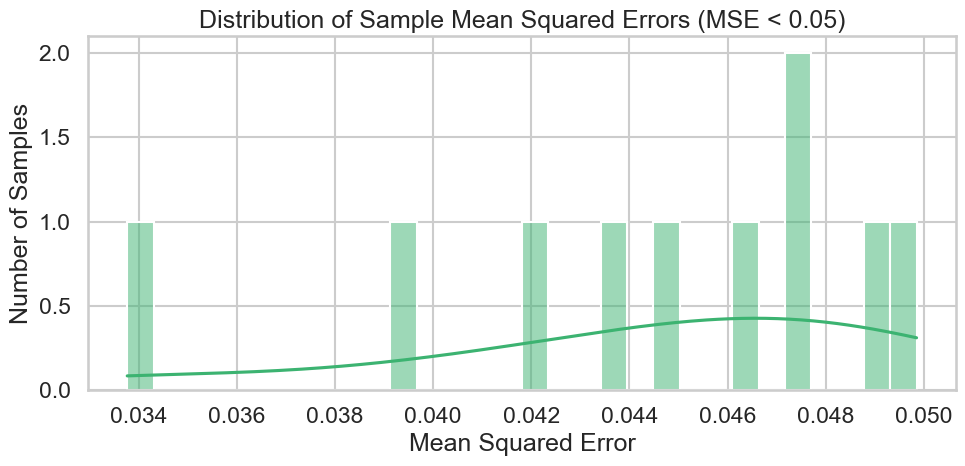


Table: Samples with Median Squared Error < 0.050 (sorted ascending)


,LOO sample,median_squared_error
0,A2058_SKIN,0.033768
1,HS294T_SKIN,0.039427
2,SW620_LARGE_INTESTINE,0.042126
3,SKHEP1_LIVER,0.043769
4,JIMT1_BREAST,0.044967
5,HCC1954_BREAST,0.046593
6,PATU8988T_PANCREAS,0.047211
7,CAL51_BREAST,0.047687
8,SH4_SKIN,0.049021
9,A375_SKIN,0.049851


In [137]:
# Mean Squared Error per sample + threshold plot (< 0.05)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

threshold = 0.05

# mask + subset for plotting
mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.1: 118


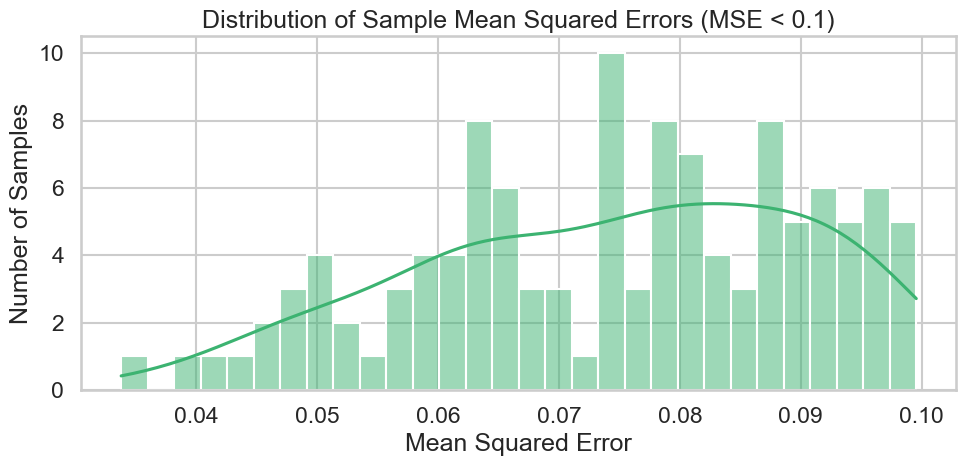

Saved CSV -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\03. elasticNet\model_results\exports\samples_median_squared_error_lt_0p1_20251113-132154.csv

Table: Samples with Median Squared Error < 0.100 (sorted ascending)


,LOO sample,median_squared_error
0,A2058_SKIN,0.033768
1,HS294T_SKIN,0.039427
2,SW620_LARGE_INTESTINE,0.042126
3,SKHEP1_LIVER,0.043769
4,JIMT1_BREAST,0.044967
5,HCC1954_BREAST,0.046593
6,PATU8988T_PANCREAS,0.047211
7,CAL51_BREAST,0.047687
8,SH4_SKIN,0.049021
9,A375_SKIN,0.049851


In [138]:
# Mean Squared Error per sample + threshold plot (< 0.1)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

threshold = 0.1

# mask + subset for plotting
mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )

    # --- SAVE TABLE ---
    from pathlib import Path
    from datetime import datetime

    out_dir = Path("exports")
    out_dir.mkdir(parents=True, exist_ok=True)

    stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
    base = f"samples_median_squared_error_lt_{threshold}".replace(".", "p")

    csv_path = out_dir / f"{base}_{stamp}.csv"

    table.to_csv(csv_path, index=False)
    print(f"Saved CSV -> {csv_path.resolve()}")

    # --- display nicely in notebooks ---
    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.2: 313


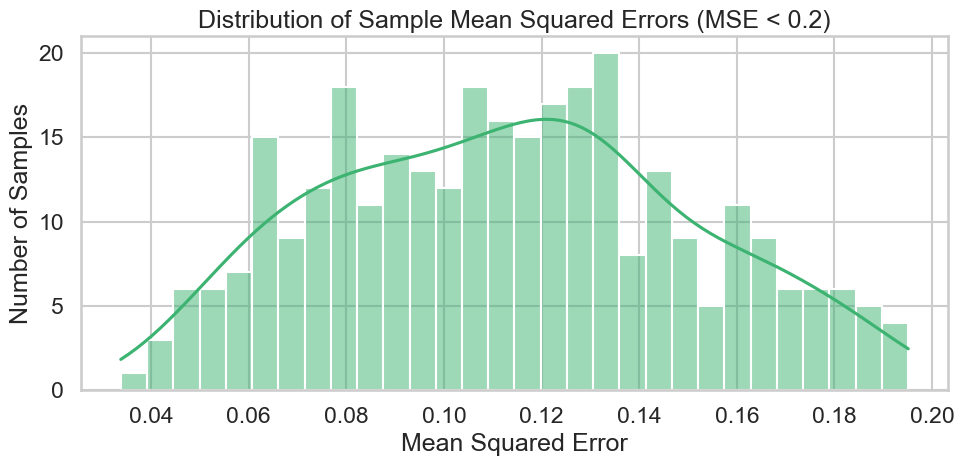


Table: Samples with Median Squared Error < 0.200 (sorted ascending)


In [139]:
threshold = 0.2

mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.3: 351


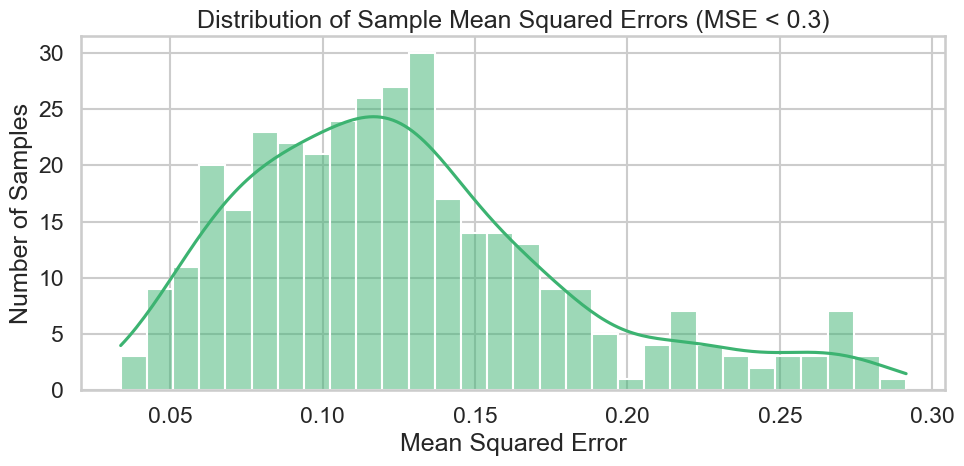


Table: Samples with Median Squared Error < 0.300 (sorted ascending)


In [140]:
threshold = 0.3

mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


### Cosine similarity

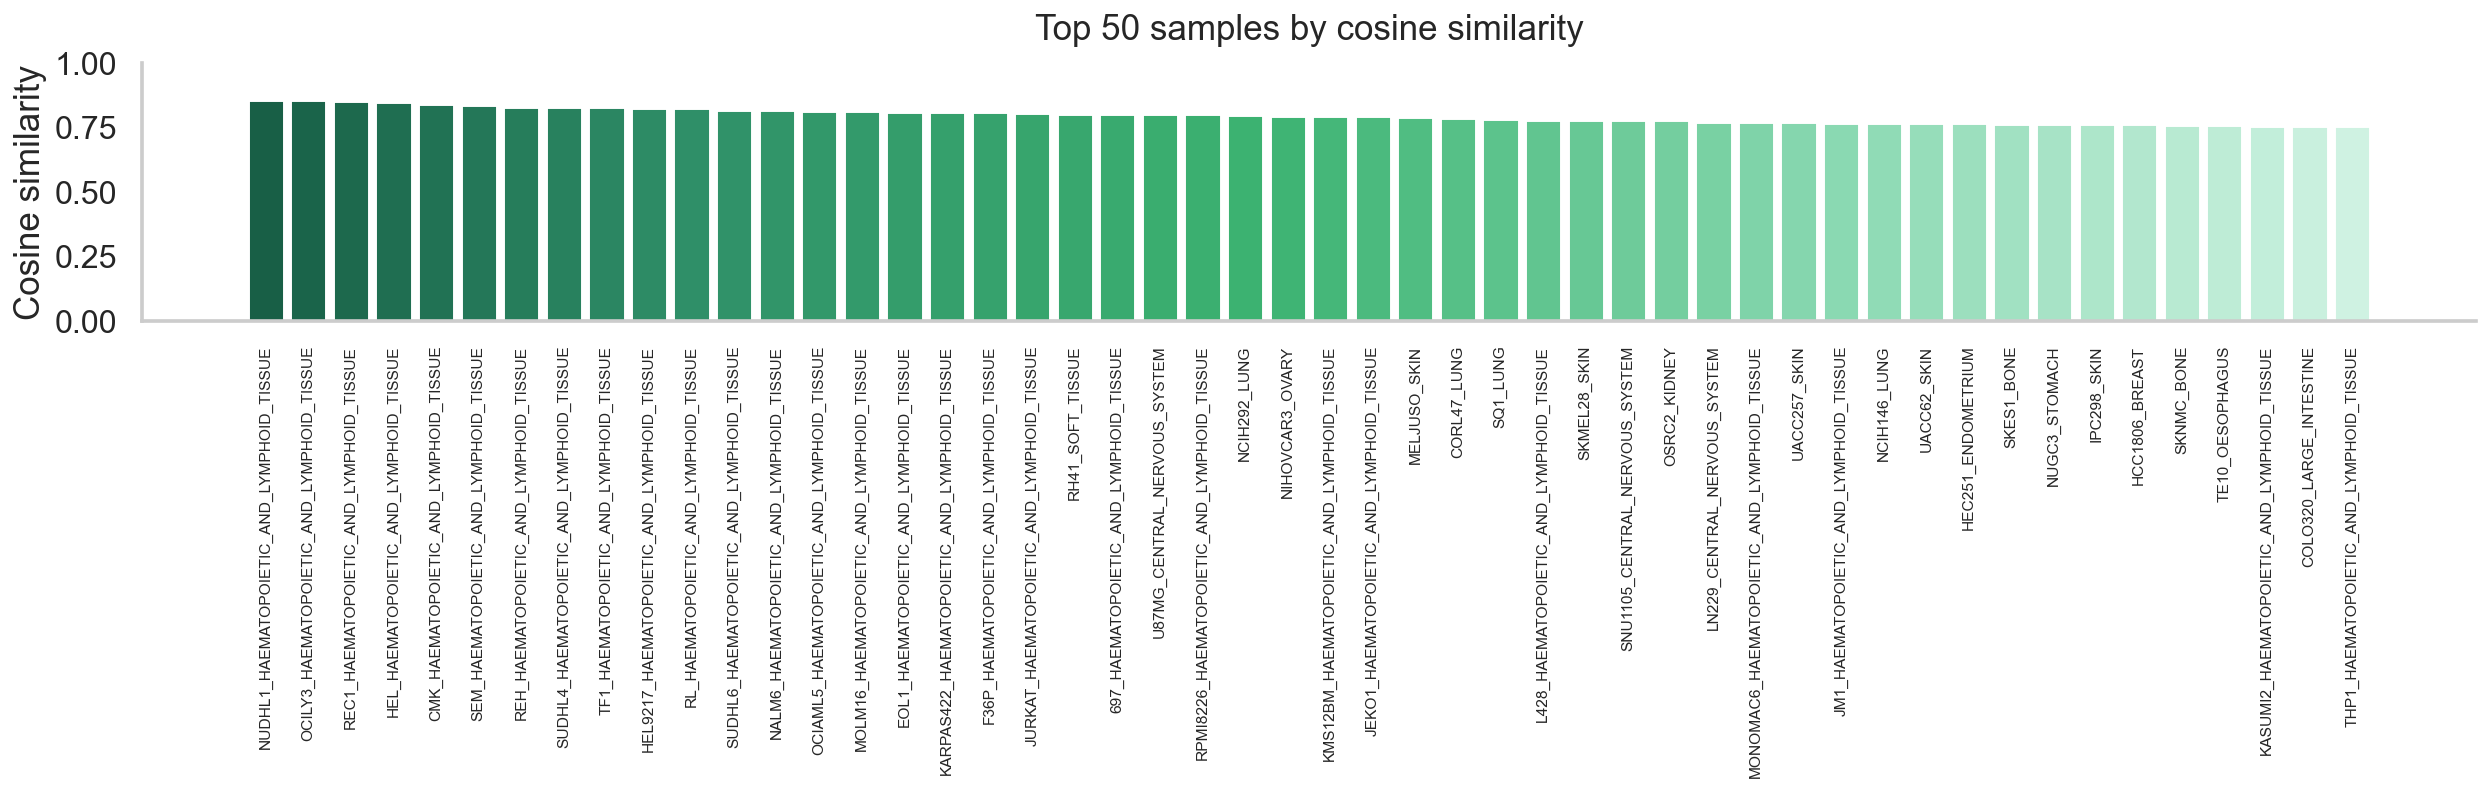

In [141]:
# Top 50 samples by cosine similarity — vertical bars, Medium SeaGreen gradient
# Build samples_df if it doesn't already exist
try:
    samples_df
except NameError:
    sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"
    if "squared_error" not in combined_df.columns:
        combined_df = combined_df.copy()
        combined_df["squared_error"] = (combined_df["true"] - combined_df["predicted"])**2

    samples_df = (
        clean.groupby(sample_col, sort=False)
        .apply(lambda g: pd.Series({
            "n_proteins": len(g),
            "mse": g["squared_error"].mean(),
            "cosine_similarity": _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()),
            "pearson_corr": g["true"].corr(g["predicted"]),
        }))
        .reset_index()
        .rename(columns={sample_col: "sample"})
    )

# Sort & take top K
k = 50
df_top = (
    samples_df[["sample", "cosine_similarity"]]
    .dropna()
    .sort_values("cosine_similarity", ascending=False)
    .head(k)
)

vals   = df_top["cosine_similarity"].to_numpy()
labels = df_top["sample"].astype(str).to_numpy()

# Medium SeaGreen tonality (deep green → MediumSeaGreen → pale mint)
seagreen_cmap = LinearSegmentedColormap.from_list(
    "seagreen_ramp",
    ["#0f4d3a", "#2f8f68", "#3CB371", "#8ad9b2", "#d7f5e8"]  # tweak if we want it cooler/warmer
)
colors = seagreen_cmap(np.linspace(0.07, 0.97, len(vals)))  # smooth rank-based gradient

fig, ax = plt.subplots(figsize=(18, 6), dpi=140)
x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85)

# Labels & limits
ax.set_title("Top 50 samples by cosine similarity", pad=12)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_ylim(0, max(1.0, vals.max() + 0.05))

# Tidy up
ax.grid(False, which='both')
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


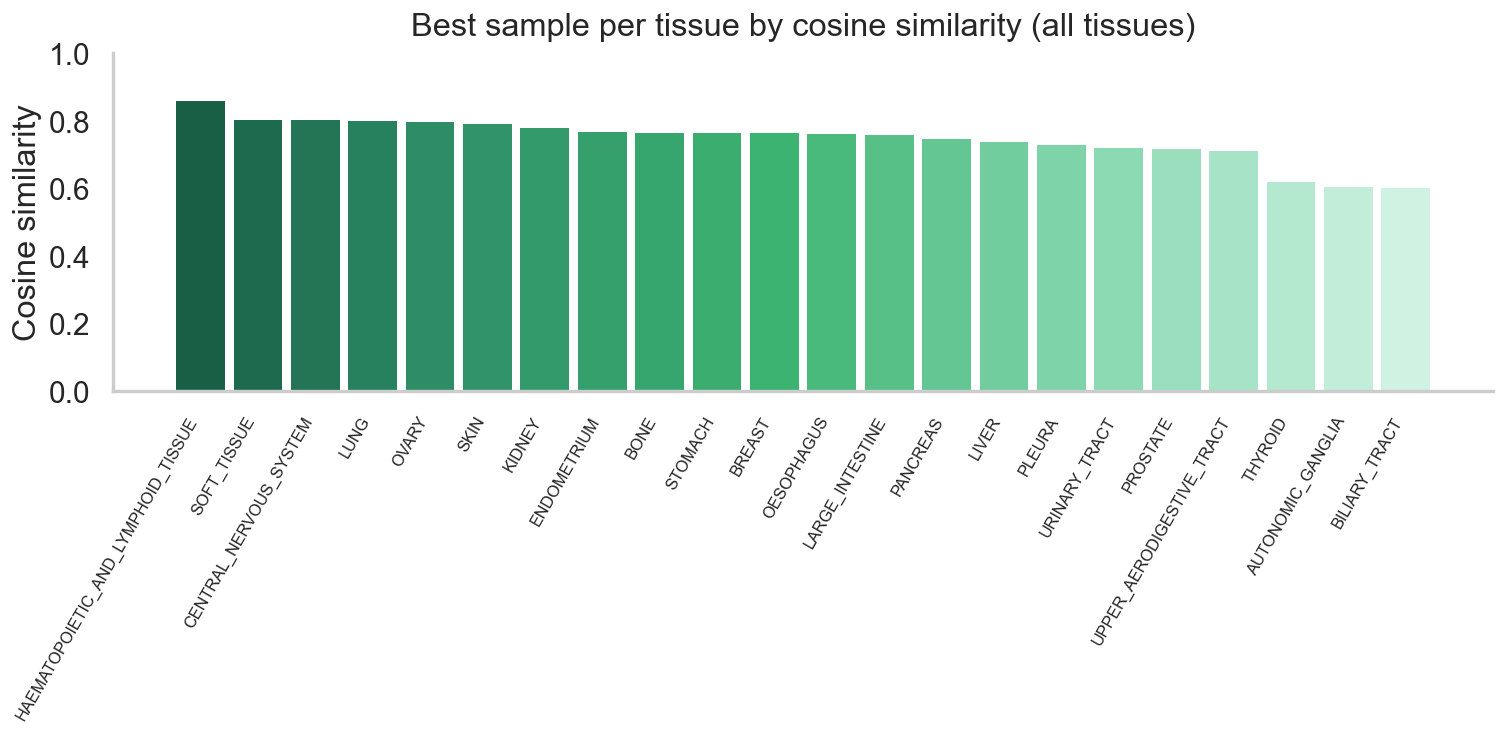

In [142]:
s = samples_df['sample'].astype(str).str.strip()
parts = s.str.split('_', n=1, expand=True)     # use n=1 as a keyword
samples_df['tissue'] = parts[1].where(parts[1].notna() & (parts[1] != ''), parts[0])

# keep one sample per tissue: the one with the highest cosine
df_best = (samples_df.dropna(subset=['tissue','cosine_similarity'])
                     .sort_values('cosine_similarity', ascending=False)
                     .drop_duplicates(subset=['tissue'], keep='first'))

# data for plotting (ALL tissues)
vals   = df_best['cosine_similarity'].to_numpy()
labels = df_best['tissue'].astype(str).to_numpy()

# Medium SeaGreen gradient (deep → light)
seagreen_cmap = LinearSegmentedColormap.from_list(
    "seagreen_ramp", ["#0f4d3a", "#2f8f68", "#3CB371", "#8ad9b2", "#d7f5e8"]
)
colors = seagreen_cmap(np.linspace(0.07, 0.97, len(vals)))

# dynamic width to fit all tissues
fig_w = max(12, 0.35 * len(vals))
fig, ax = plt.subplots(figsize=(fig_w, 6), dpi=130)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85, edgecolor='none', linewidth=0)

ax.set_title("Best sample per tissue by cosine similarity (all tissues)", pad=10)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

# clean look (no grid/edges)
ax.grid(False, which='both')
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [143]:
# total rows considered (robust to NaNs)
total = int(samples_df['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((samples_df['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_samples": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total Samples considered: {total}\n")
print(summary.to_string())


Total Samples considered: 369

           n_samples % of total
threshold                      
>0.5             348      94.3%
>0.6             275      74.5%
>0.7             121      32.8%
>0.8              23       6.2%


In [144]:
# --- aggregate per tissue (MEAN)
tissue_table = (
    samples_df.dropna(subset=['tissue'])
              .groupby('tissue', as_index=False)
              .agg(n_samples=('sample', 'nunique'),
                   cosine_similarity=('cosine_similarity', 'mean'),
                   mse=('mse', 'mean'))
              .sort_values('cosine_similarity', ascending=False)
)

# --- display
try:
    display(
        tissue_table.style
            .format({'cosine_similarity': '{:.4f}', 'mse': '{:.6f}', 'n_samples': '{:d}'})
            .set_properties(subset=['tissue'], **{'font-weight': 'bold'})
    )
except Exception:
    print(tissue_table.to_string(index=False))

,tissue,n_samples,cosine_similarity,mse
6,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,40,0.7730,0.433133
14,PLEURA,2,0.7133,0.278291
5,ENDOMETRIUM,14,0.6790,0.358543
16,SKIN,33,0.6701,0.259902
17,SOFT_TISSUE,8,0.6691,0.373777
7,KIDNEY,11,0.6691,0.338391
3,BREAST,30,0.6685,0.313019
4,CENTRAL_NERVOUS_SYSTEM,13,0.6652,0.401289
9,LIVER,14,0.6629,0.270293
11,OESOPHAGUS,14,0.6566,0.327228


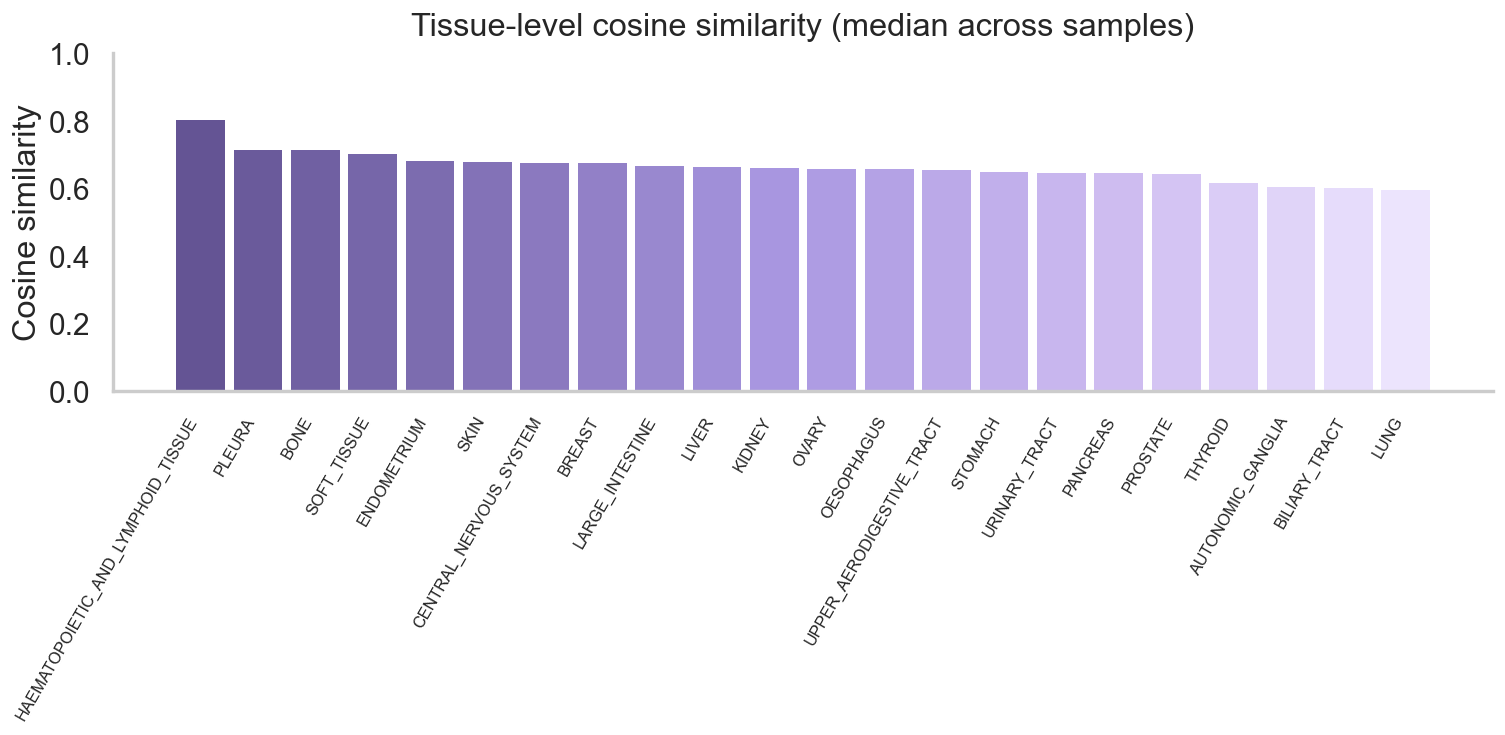

In [145]:

# --- aggregate per tissue (median; switch to 'mean' if preferred)
tissue_stats = (
    samples_df.dropna(subset=['tissue', 'cosine_similarity'])
              .groupby('tissue')
              .agg(cosine_similarity=('cosine_similarity', 'median'),
                   n_samples=('sample', 'nunique'))
              .sort_values('cosine_similarity', ascending=False)
)

vals   = tissue_stats['cosine_similarity'].to_numpy()
labels = tissue_stats.index.astype(str).to_numpy()

# Light purple (lilac) gradient
lilac_cmap = LinearSegmentedColormap.from_list(
    "lilac_ramp",
    ["#5b4b8a", "#7e6db1", "#a896e0", "#cdbbf0", "#f0e9ff"] 
)
colors = lilac_cmap(np.linspace(0.07, 0.97, len(vals)))

# dynamic width for all tissues
fig_w = max(12, 0.35 * len(vals))
fig, ax = plt.subplots(figsize=(fig_w, 6), dpi=130)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85, edgecolor='none', linewidth=0)

ax.set_title("Tissue-level cosine similarity (median across samples)", pad=10)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

ax.set_axisbelow(True)
ax.grid(False, which='both')

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Other statistical plots on Samples

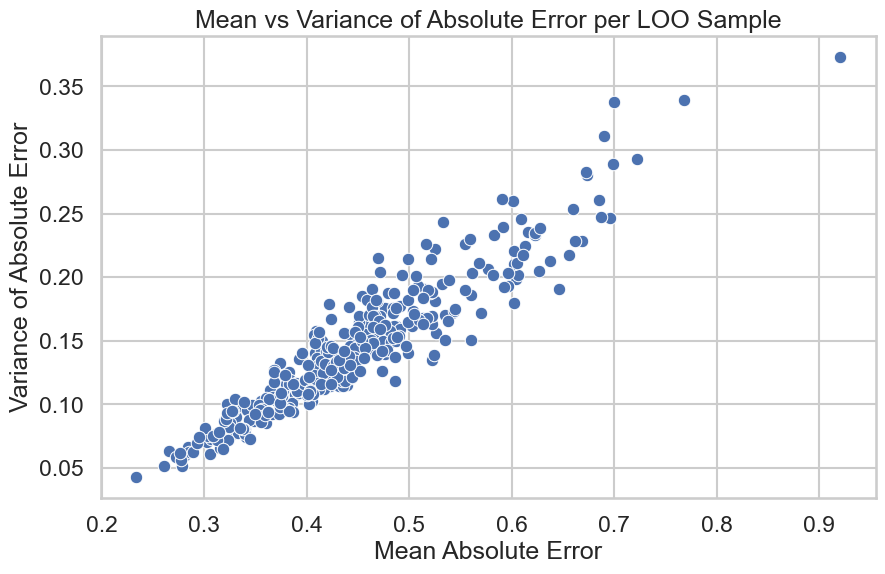

In [146]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


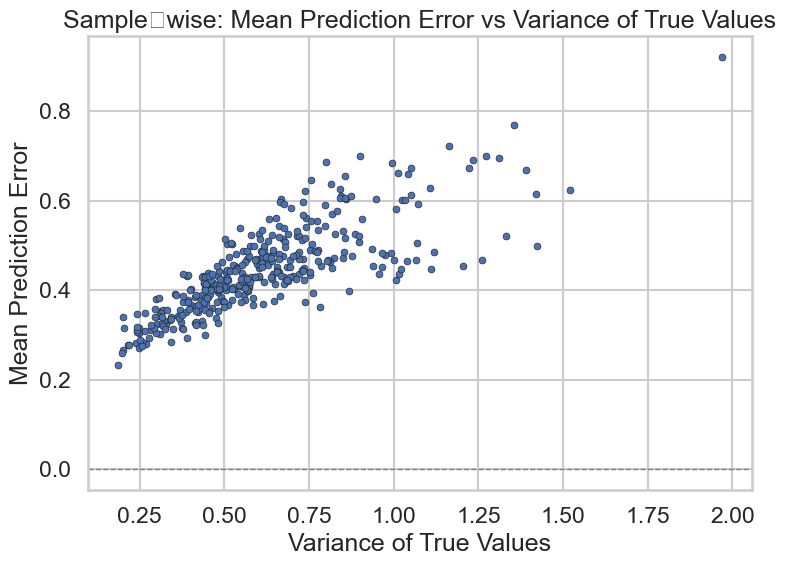

In [147]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

## Boxplot Protein and Samples

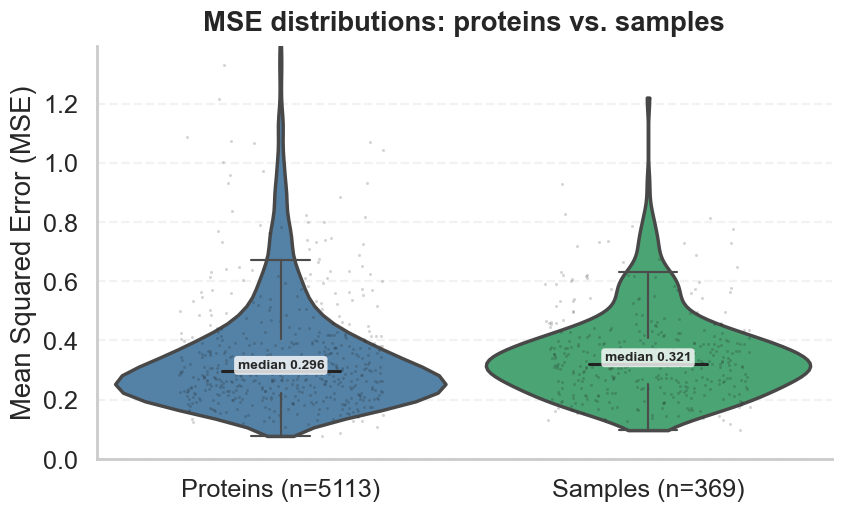

In [148]:
# Visually enhanced box/violin plot of MSE: proteins vs samples

df = combined_df.copy()
sample_col = "LOO sample" if "LOO sample" in df.columns else "sample"

# ensure squared_error exists
if "squared_error" not in df.columns:
    df["squared_error"] = (df["true"] - df["predicted"])**2

# per-group MSE
protein_mse = (
    df.groupby("protein", sort=False)["squared_error"]
      .mean()
      .reset_index()
      .rename(columns={"squared_error": "mse"})
)
sample_mse = (
    df.groupby(sample_col, sort=False)["squared_error"]
      .mean()
      .reset_index()
      .rename(columns={"squared_error": "mse", sample_col: "sample"})
)

# tidy for plotting
plot_df = pd.concat(
    [protein_mse.assign(group="Proteins")[["group", "mse"]],
     sample_mse.assign(group="Samples")[["group", "mse"]]],
    ignore_index=True
)

# aesthetics
palette = {"Proteins": "#4682B4",  # steelblue
           "Samples":  "#3CB371"}  # mediumseagreen
sns.set_theme(style="whitegrid", context="talk")

# y-limit trimmed to reduce extreme outlier pull
ymax = np.percentile(plot_df["mse"], 99.5)
ymax = float(np.clip(ymax * 1.05, 0.1, None))  # small buffer

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)  # was (18, 6), 140


# violin (soft fill, no inner lines)
sns.violinplot(
    data=plot_df, x="group", y="mse",
    palette=palette, inner=None, cut=0, width=0.9, alpha=0.6, ax=ax
)

# box overlay (thin, clean)
sns.boxplot(
    data=plot_df, x="group", y="mse",
    width=0.32, showcaps=True, showfliers=False, boxprops={"facecolor": "white", "alpha": 0.9},
    medianprops={"linewidth": 2, "color": "#222"},
    whiskerprops={"linewidth": 1.4},
    capprops={"linewidth": 1.4},
    ax=ax
)

# light jittered points (subsample to keep it crisp)
pts = (
    plot_df.groupby("group", group_keys=False)
           .apply(lambda g: g.sample(n=min(500, len(g)), random_state=0))
)
sns.stripplot(
    data=pts, x="group", y="mse",
    color="k", alpha=0.18, size=2, jitter=0.28, ax=ax, zorder=1
)

# titles, labels, and counts
counts = {"Proteins": len(protein_mse), "Samples": len(sample_mse)}
ax.set_title("MSE distributions: proteins vs. samples", pad=10, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Mean Squared Error (MSE)")
ax.set_xticklabels([
    f"Proteins (n={counts['Proteins']})",
    f"Samples (n={counts['Samples']})"
])

# median annotations
meds = plot_df.groupby("group")["mse"].median().to_dict()
for i, g in enumerate(["Proteins", "Samples"]):
    m = meds[g]
    ax.text(i, m, f"median {m:.3f}", ha="center", va="bottom",
            fontsize=9, weight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.8))

# tidy up
ax.set_ylim(0, ymax)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


# MAE vs Prot- Encoding Gene correlations

In [149]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


# Cluster-Wise analysis

In [150]:
clusters = pd.read_csv("res_data/protein_clusters_k3.csv")

In [151]:
clusters

,Protein,Cluster
0,A2M,3
1,AAAS,3
2,AACS,3
3,AAGAB,1
4,AAK1,2
...,...,...
5108,ZRANB2,1
5109,ZW10,3
5110,ZWILCH,1
5111,ZYX,3


Distributions

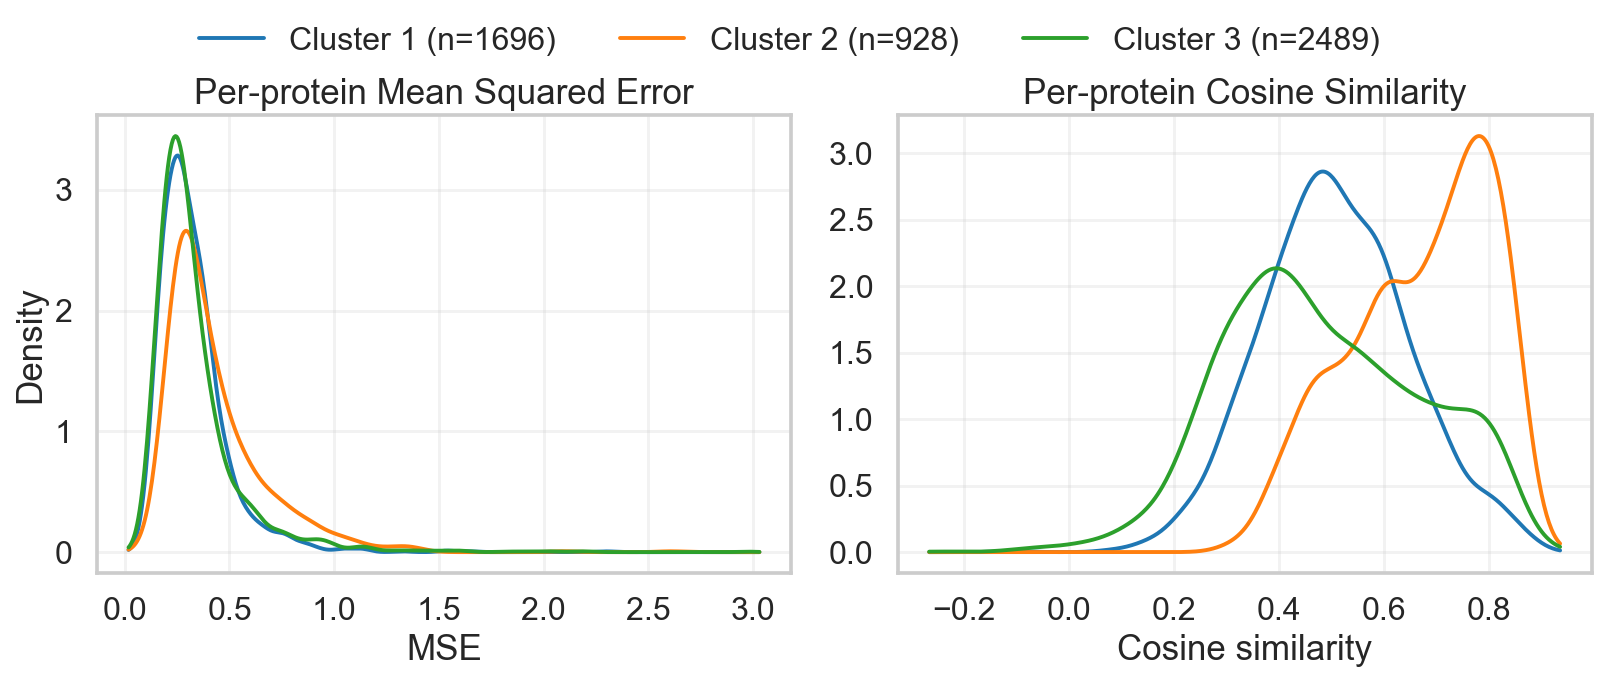

In [152]:
# Side-by-side KDEs by cluster: per-protein MSE (left) and cosine similarity (right)
# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # blue, orange, green

# --- helpers
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

def _pad_range(x):
    x = np.asarray(x)
    xmin, xmax = float(np.min(x)), float(np.max(x))
    span = max(xmax - xmin, 1e-6)
    pad = 0.02 * span
    return xmin - pad, xmax + pad

# --- inputs
dfc = combined_df.copy()

# ensure squared_error exists
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# --- per-protein metrics
prot_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .mean()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
)

prot_cos = (
    dfc.groupby("protein", sort=False)
       .apply(lambda g: _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()))
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
       .dropna(subset=["cosine_similarity"])
)

# merge with cluster mapping (expects columns: Protein, Cluster)
df_mse = prot_mse.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
df_cos = prot_cos.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")

# --- x-ranges
xmin_mse, xmax_mse = _pad_range(df_mse["mse"].values)
xmin_cos, xmax_cos = _pad_range(df_cos["cosine_similarity"].values)
xr_mse = np.linspace(xmin_mse, xmax_mse, 512)
xr_cos = np.linspace(xmin_cos, xmax_cos, 512)

# --- plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=140)

# Left: MSE KDEs
for c in sorted(df_mse["Cluster"].dropna().unique()):
    vals = df_mse.loc[df_mse["Cluster"] == c, "mse"].to_numpy()
    if len(vals) >= 2:
        kde = gaussian_kde(vals)  # tweak bandwidth via bw_method=0.3 if desired
        ax1.plot(xr_mse, kde(xr_mse), lw=2, color=palette.get(c, "#333"),
                 label=f"Cluster {c} (n={len(vals)})")
    elif len(vals) == 1:  # fallback for very small groups
        ax1.axvline(vals[0], ymax=0.12, lw=2, color=palette.get(c, "#333"),
                    label=f"Cluster {c} (n=1)")

ax1.set_title("Per-protein Mean Squared Error")
ax1.set_xlabel("MSE")
ax1.set_ylabel("Density")
ax1.grid(alpha=0.25)

# Right: Cosine similarity KDEs
for c in sorted(df_cos["Cluster"].dropna().unique()):
    vals = df_cos.loc[df_cos["Cluster"] == c, "cosine_similarity"].to_numpy()
    if len(vals) >= 2:
        kde = gaussian_kde(vals)
        ax2.plot(xr_cos, kde(xr_cos), lw=2, color=palette.get(c, "#333"))
    elif len(vals) == 1:
        ax2.axvline(vals[0], ymax=0.12, lw=2, color=palette.get(c, "#333"))

ax2.set_title("Per-protein Cosine Similarity")
ax2.set_xlabel("Cosine similarity")
ax2.grid(alpha=0.25)

# Shared legend (from left subplot)
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.01))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Scatterplot

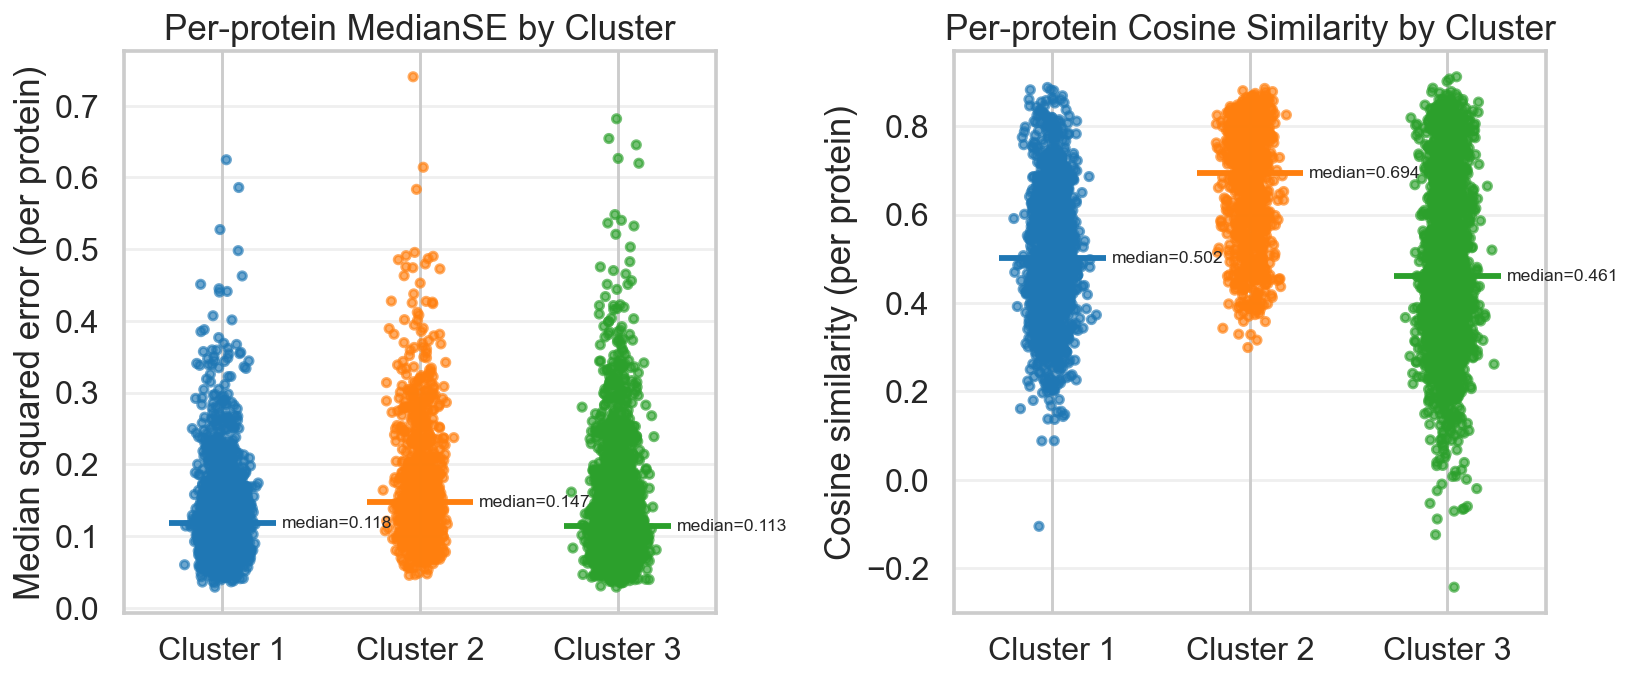

In [153]:
# Side-by-side jittered scatters by cluster: per-protein MSE (left) and cosine similarity (right)

# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # steelblue, orange, green

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# --- build per-protein metrics from combined_df and merge clusters
dfc = combined_df.copy()
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# per-protein MSE
df_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .median()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
    .merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
)

# per-protein cosine similarity
df_cos = (
    dfc.groupby("protein", sort=False)
       .apply(lambda g: _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()))
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
       .dropna(subset=["cosine_similarity"])
    .merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
)

# --- helper for jittered scatter with median lines
#“Jittered” just means we add a tiny bit of random noise to each point’s position along the x-axis
# so overlapping points don’t sit exactly on top of each other. 
# It makes dense, discrete groups (like clusters 1/2/3) easier to read.
def jitter_scatter(ax, clusters_col, y_col, title, ylabel, seed=0):
    rng = np.random.default_rng(seed)
    x = clusters_col.astype(int).to_numpy()
    y = y_col.to_numpy()

    # horizontal jitter so points don't overlap
    x_jittered = x + rng.normal(0, 0.06, size=len(x))
    colors = [palette.get(int(c), "#333") for c in x]

    ax.scatter(x_jittered, y, s=18, alpha=0.65, c=colors)

    # per-cluster medians
    for c in sorted(pd.unique(clusters_col)):
        yc = y_col[clusters_col == c]
        if len(yc) == 0: 
            continue
        med = float(np.median(yc))
        ax.hlines(med, c - 0.27, c + 0.27, colors=palette.get(int(c), "#333"), linewidth=3)
        ax.text(c + 0.3, med, f"median={med:.3f}", fontsize=9, va="center")

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Cluster 1", "Cluster 2", "Cluster 3"])
    ax.set_xlim(0.5, 3.5)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

# --- plot side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=140)

jitter_scatter(ax1, df_mse["Cluster"], df_mse["mse"],
               title="Per-protein MedianSE by Cluster",
               ylabel="Median squared error (per protein)",
               seed=0)

jitter_scatter(ax2, df_cos["Cluster"], df_cos["cosine_similarity"],
               title="Per-protein Cosine Similarity by Cluster",
               ylabel="Cosine similarity (per protein)",
               seed=1)  # different seed to vary jitter pattern

plt.tight_layout()
plt.show()
